# Trabajo Práctico Final — Aprendizaje de Máquina
## Clasificación multiclase de la severidad legal de denuncias del NYPD
### ¿Cuánto puede aprender un modelo del contexto si eliminamos las variables que ya contienen la respuesta?

**Materia:** Aprendizaje de Máquina — CEIA 27Co2026  
**Dataset:** *NYPD Complaint Data Current (Year To Date)*  
**Período de estudio:** denuncias reportadas entre **01/01/2026 y 30/06/2026**  
**Variable objetivo:** `LAW_CAT_CD`, `VIOLATION`, `MISDEMEANOR`, `FELONY`  
**Integrantes:** Maria Celeste Corominas - Christian Marcelo Yanez Flores
**Grupo:** 4
**Fecha:** 17/10/2026

---

## Resumen ejecutivo

Este trabajo investiga si es posible inferir la categoría legal registrada de una denuncia del NYPD a partir de información contextual (momento, ubicación, tipo de lugar y jurisdicción) sin utilizar variables que describen el delito de manera tan directa que producirían data leakage.

La investigación busca responder:

> **¿Existe señal predictiva suficiente en el contexto como para superar reglas simples y, si existe, qué familia de modelos ofrece el mejor equilibrio entre desempeño, estabilidad, costo e interpretabilidad?**

Se construye un experimento reproducible con dos baselines, regresión logística, árbol de decisión, Bagging, Random Forest y Gradient Boosting; validación cruzada estratificada; ajuste de hiperparámetros sin utilizar test; una regla de parsimonia; análisis explícito del trade-off entre accuracy y F1 macro; experimento controlado de `class_weight`; matriz de confusión; intervalo bootstrap; importancia por permutación y un snapshot congelado de los datos.

El trabajo se apoya en el TP previo de Análisis de Datos, pero el foco de esta entrega está en la aplicación, selección y evaluación de modelos de Machine Learning.

# 1. Propuesta de investigación

## 1.1 Problema

`LAW_CAT_CD` identifica el nivel legal registrado del hecho: `VIOLATION`, `MISDEMEANOR` o `FELONY`. Por lo tanto, el problema es de clasificación supervisada multiclase.

Sin embargo, el dataset contiene otras variables (`PD_CD`, `PD_DESC`, `KY_CD`, `OFNS_DESC`) fuertemente vinculadas con la clasificación específica del delito. Si se las utilizara como predictores, sería posible construir un modelo con métricas muy altas sin responder una pregunta predictiva interesante.

## 1.2 Pregunta de investigación

> **¿Hasta qué punto puede inferirse `LAW_CAT_CD` a partir de variables contextuales, excluyendo las variables que codifican directa o casi directamente el delito?**

## 1.3 ¿Por qué vale la pena evaluarlo?

Este planteo permite estudiar tres cuestiones centrales del curso:

1. si existe realmente un patrón aprendible una vez eliminado el leakage;
2. qué complejidad de modelo se justifica para capturarlo;
3. cómo evaluar correctamente una solución cuando las clases no están perfectamente balanceadas.

## 1.4 Qué pretendemos encontrar o descubrir

La investigación busca determinar:

- si los modelos aprendidos superan un baseline trivial;
- si superan también una regla contextual simple;
- si una frontera lineal resulta suficiente;
- cuánto aporta pasar de un árbol individual a ensambles;
- si Bagging, Random Forest o Boosting justifican su mayor complejidad;
- en qué clases y pares de clases se concentran los errores;
- qué variables contextuales usa más el modelo final;
- si las diferencias entre algoritmos son suficientemente grandes como para hablar de una mejora real y no de unas pocas milésimas.

## 1.5 Hipótesis de trabajo

- **H1:** existe señal predictiva contextual por encima de los baselines.
- **H2:** las relaciones no son puramente lineales, por lo que algún modelo basado en árboles podría mejorar el F1 macro.
- **H3:** no se presupone que el modelo más complejo vaya a ganar; si las diferencias son pequeñas, se priorizará parsimonia.

# 2. Fuentes y marco de referencia

**Dataset**

El conjunto de datos utilizado es NYPD Complaint Data Current (Year To Date),
publicado por NYC Open Data y provisto por el New York City Police Department
(NYPD), con identificador `5uac-w243`.

La base contiene registros de denuncias válidas informadas al NYPD e incluye
información temporal, geográfica y contextual sobre cada hecho. Entre otras
variables, incorpora la fecha y hora de ocurrencia y de reporte, ubicación,
tipo de lugar, jurisdicción, condición de hecho consumado o tentado y nivel
legal de la infracción.

La variable `LAW_CAT_CD` indica el nivel legal asignado al hecho y constituye
la variable objetivo de este trabajo. El dataset contempla tres categorías:

- **VIOLATION:** corresponde a una infracción para la cual no puede imponerse
  una pena de prisión superior a 15 días. De acuerdo con la legislación del
  Estado de Nueva York, una *violation* no se considera un crimen en sentido
  estricto.

- **MISDEMEANOR:** corresponde a un delito para el cual puede imponerse una
  pena superior a 15 días, pero no superior a un año de prisión.

- **FELONY:** corresponde a un delito para el cual puede imponerse una pena
  superior a un año de prisión.

Por lo tanto, en este trabajo las tres clases pueden interpretarse, de forma
simplificada, como niveles crecientes de severidad penal:

`VIOLATION , MISDEMEANOR , FELONY`

La fuente `Current (Year To Date)` es dinámica y se actualiza periódicamente.
Para garantizar la reproducibilidad, el análisis se realiza sobre una copia
local del archivo descargado desde NYC Open Data. El snapshot utilizado en
este trabajo comprende registros correspondientes al período enero-junio de
2026.

Fuentes oficiales:

- NYC Open Data / NYPD — *NYPD Complaint Data Current (Year To Date)*:  
  https://data.cityofnewyork.us/Public-Safety/NYPD-Complaint-Data-Current-Year-To-Date-/5uac-w243

- API de NYC Open Data:  
  https://data.cityofnewyork.us/resource/5uac-w243.csv

- New York State Penal Law, § 10.00 — definiciones de *violation*,
  *misdemeanor* y *felony*:  
  https://www.nysenate.gov/legislation/laws/PEN/10.00


**Material de la materia**

Como marco metodológico se utiliza el repositorio oficial de la asignatura
Aprendizaje de Máquina de la Carrera de Especialización en Inteligencia
Artificial de FIUBA:

https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprMaqI_CEIA

Se toman como referencia los enfoques trabajados en la materia sobre modelos
de clasificación, selección de hiperparámetros, máquinas de vectores de
soporte, árboles de decisión, métodos de ensamble, aprendizaje no supervisado
y calibración.

Para la comparación de modelos se adopta especialmente el criterio de no
considerar diferencias pequeñas en las métricas como evidencia suficiente de
superioridad. La selección se analiza conjuntamente con la variabilidad
obtenida mediante validación cruzada, el desempeño sobre datos no utilizados
durante el ajuste y la complejidad adicional introducida por cada alternativa.


**Bibliografía**

- Bruce, P., Bruce, A. y Gedeck, P. (2020).
  *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R
  and Python*. 2nd ed. O'Reilly Media.

- James, G., Witten, D., Hastie, T., Tibshirani, R. y Taylor, J. (2023).
  *An Introduction to Statistical Learning: with Applications in Python*.
  Springer.

- Hastie, T., Tibshirani, R. y Friedman, J. (2009).
  *The Elements of Statistical Learning: Data Mining, Inference, and
  Prediction*. 2nd ed. Springer.

- Breiman, L. (2001).
  “Random Forests”. *Machine Learning*, 45, 5–32.
  https://doi.org/10.1023/A:1010933404324

- scikit-learn developers.
  *scikit-learn User Guide and API Reference*.
  https://scikit-learn.org/stable/

- New York State Senate.
  *New York Penal Law § 10.00 — Definitions of terms of general use in this
  chapter*.
  https://www.nysenate.gov/legislation/laws/PEN/10.00

# 3. Decisiones heredadas del TP de Análisis de Datos

Para no convertir esta materia en una repetición completa del EDA anterior, partimos de conclusiones ya documentadas:

- `LAW_CAT_CD` presenta un desbalance moderado;
- varios faltantes son estructurales;
- coordenadas periféricas y demoras largas pueden ser observaciones legítimas;
- la demora entre ocurrencia y reporte tiene cola derecha pronunciada y se beneficia de `log1p`;
- hora, mes y día de semana son variables periódicas y se representan de manera cíclica;
- `PD_CD`, `PD_DESC`, `KY_CD` y `OFNS_DESC` introducen *leakage*;
- PCA redujo dimensionalidad, pero disminuyó interpretabilidad y no mostró una separación clara del target.

**Decisión para este TP:** no usamos PCA en el modelo principal y trabajamos con un conjunto contextual compacto e interpretable.

# 4. Entorno, reproducibilidad y configuración

Se fija una única semilla y se documentan las versiones del entorno. Esto permite reproducir particiones, muestreos y modelos estocásticos, además de explicar diferencias si la notebook se ejecuta en otra máquina.

In [3]:
# ============================================================
# ENTORNO, IMPORTS Y CONFIGURACIÓN GLOBAL
# ============================================================

# Bibliotecas estándar utilizadas para rutas, versiones, tiempos,
# advertencias y cálculo de la huella SHA-256 del dataset.

from pathlib import Path
import platform
import hashlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

# Componentes de scikit-learn utilizados para construir transformadores,
# estimadores, pipelines, validación y métricas.
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, log_loss,
)
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

# Configuración de salida para mantener la notebook legible durante la ejecución.
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

# Parámetros globales de reproducibilidad y presupuesto computacional.
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_MUESTRA_CV = 50_000
N_ITER_TUNING = 12
N_SPLITS_CV = 3

# Registro de versiones para facilitar la reproducción del entorno.
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1


# 5. Carga y congelamiento del dataset

### Problema de reproducibilidad detectado

`NYPD Complaint Data Current (Year To Date)` es un recurso dinámico. Aunque filtremos enero–junio de 2026, en un año futuro el endpoint *Current YTD* dejará de representar 2026.

Por eso esta versión prioriza un snapshot congelado:

`datasets/NYPD_Complaint_Data_Current_2026_Q2.csv`

### Flujo

1. busca primero el snapshot congelado;
2. acepta también las rutas históricas usadas en el TP previo;
3. solo si no existe ningún archivo local, consulta la API oficial;
4. filtra exactamente `RPT_DT` entre 01/01/2026 y 30/06/2026;
5. si la carga vino de la API, intenta guardar el snapshot congelado;
6. calcula e informa un SHA-256 del archivo cuando está disponible.

### Por qué

La notebook, el código y la semilla no alcanzan para reproducir un experimento si el dataset cambia. La versión entregada debe acompañarse con este snapshot o con un enlace persistente al archivo exacto.

In [4]:
# ============================================================
# 5. CARGA DEL SNAPSHOT
# ============================================================

SNAPSHOT_NAME = "NYPD_Complaint_Data_Current_2026_Q2.csv"

RUTAS_LOCALES = [
    Path("datasets") / SNAPSHOT_NAME,
    Path("../datasets") / SNAPSHOT_NAME,
    Path("./datasets/NYPD_Complaint_Data_Current.csv"),
    Path("../datasets/NYPD_Complaint_Data_Current.csv"),
    Path("NYPD_Complaint_Data_Current.csv"),
]

URL_OFICIAL = (
    "https://data.cityofnewyork.us/resource/5uac-w243.csv"
    "?$limit=500000"
)

ruta_local = next(
    (ruta for ruta in RUTAS_LOCALES if ruta.exists()),
    None,
)

cargado_desde_api = False

if ruta_local is not None:
    df = pd.read_csv(
        ruta_local,
        na_values=["(null)", ""],
        low_memory=False,
    )
    fuente_carga = f"Archivo local: {ruta_local}"
else:
    # Fallback: útil para ejecutar la notebook, pero NO reemplaza
    # la necesidad de congelar el snapshot para la entrega.
    df = pd.read_csv(
        URL_OFICIAL,
        na_values=["(null)", ""],
        low_memory=False,
    )
    fuente_carga = "NYC Open Data — Socrata API"
    cargado_desde_api = True

df.columns = [
    str(col).strip().upper()
    for col in df.columns
]

print("Fuente utilizada:", fuente_carga)
print(f"Dimensiones cargadas: {df.shape[0]:,} × {df.shape[1]}")
display(df.head(3))

Fuente utilizada: NYC Open Data — Socrata API
Dimensiones cargadas: 279,513 × 36


,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,CMPLNT_TO_DT,CMPLNT_TO_TM,CRM_ATPT_CPTD_CD,HADEVELOPT,HOUSING_PSA,JURISDICTION_CODE,JURIS_DESC,KY_CD,LAW_CAT_CD,LOC_OF_OCCUR_DESC,OFNS_DESC,PARKS_NM,PATROL_BORO,PD_CD,PD_DESC,PREM_TYP_DESC,RPT_DT,STATION_NAME,SUSP_AGE_GROUP,SUSP_RACE,SUSP_SEX,TRANSIT_DISTRICT,VIC_AGE_GROUP,VIC_RACE,VIC_SEX,X_COORD_CD,Y_COORD_CD,LATITUDE,LONGITUDE,LAT_LON,GEOCODED_COLUMN
0,321141941,123,STATEN ISLAND,2026-03-02T00:00:00.000,00:08:00,2026-03-02T00:00:00.000,00:20:00,COMPLETED,NaN,NaN,0,N.Y. POLICE DEPT,106,FELONY,FRONT OF,FELONY ASSAULT,NaN,PATROL BORO STATEN ISLAND,106.0,ASSAULT POLICE/PEACE OFFICER,RESIDENCE-HOUSE,2026-03-02T00:00:00.000,NaN,25-44,WHITE,M,NaN,25-44,UNKNOWN,L,934887.0,131256.0,40.526814,-74.177565,"(40.526814, -74.177565)",POINT (-74.177565 40.526814)
1,326554809,123,STATEN ISLAND,2026-06-12T00:00:00.000,12:50:00,2026-06-12T00:00:00.000,13:00:00,COMPLETED,NaN,NaN,0,N.Y. POLICE DEPT,578,VIOLATION,INSIDE,HARRASSMENT 2,NaN,PATROL BORO STATEN ISLAND,638.0,"HARASSMENT,SUBD 3,4,5",OTHER,2026-06-12T00:00:00.000,NaN,18-24,BLACK,F,NaN,45-64,BLACK,F,935052.0,133094.0,40.531862,-74.176985,"(40.531862, -74.176985)",POINT (-74.176985 40.531862)
2,324298851,122,STATEN ISLAND,2026-04-30T00:00:00.000,05:30:00,NaN,NaN,COMPLETED,NaN,NaN,0,N.Y. POLICE DEPT,578,VIOLATION,NaN,HARRASSMENT 2,NaN,PATROL BORO STATEN ISLAND,638.0,"HARASSMENT,SUBD 3,4,5",STREET,2026-04-30T00:00:00.000,NaN,UNKNOWN,UNKNOWN,U,NaN,45-64,WHITE,M,939698.0,139876.0,40.550500,-74.160315,"(40.5505, -74.160315)",POINT (-74.160315 40.5505)


## 5.1 Fijación del período y huella del snapshot

El archivo local puede usar fechas `MM/DD/YYYY`, mientras que la API puede devolver timestamps ISO. Se usa un parseo tolerante a ambos formatos.

Después se fija el período de reportes entre **01/01/2026 y 30/06/2026**.

Si la fuente fue la API, la notebook intenta guardar ese recorte como snapshot congelado. Finalmente se calcula SHA-256 cuando existe un archivo persistido.

In [5]:
def parsear_fecha(serie):
    try:
        return pd.to_datetime(
            serie,
            format="mixed",
            errors="coerce",
        )
    except (TypeError, ValueError):
        return pd.to_datetime(
            serie,
            errors="coerce",
        )


df["RPT_DT"] = parsear_fecha(
    df["RPT_DT"]
)

INICIO_ESTUDIO = pd.Timestamp("2026-01-01")
FIN_ESTUDIO_EXCLUSIVO = pd.Timestamp("2026-07-01")

mask_periodo = (
    (df["RPT_DT"] >= INICIO_ESTUDIO)
    & (df["RPT_DT"] < FIN_ESTUDIO_EXCLUSIVO)
)

df = df.loc[
    mask_periodo
].copy()

print(
    "Período de reportes analizado:",
    df["RPT_DT"].min(),
    "→",
    df["RPT_DT"].max(),
)
print(
    f"Registros del período: {len(df):,}"
)

# El snapshot usado en el TP previo contenía 279.513 filas.
# Si el portal revisó registros históricos, no detenemos la ejecución,
# pero dejamos la diferencia documentada.
N_ESPERADO_REFERENCIA = 279_513

if len(df) != N_ESPERADO_REFERENCIA:
    warnings.warn(
        f"El recorte contiene {len(df):,} filas y la referencia previa "
        f"era {N_ESPERADO_REFERENCIA:,}. "
        "NYC Open Data puede haber revisado registros históricos."
    )

# Si llegamos desde la API, congelamos el recorte para futuras ejecuciones.
snapshot_path = None

if cargado_desde_api:
    try:
        Path("datasets").mkdir(
            parents=True,
            exist_ok=True,
        )

        snapshot_path = (
            Path("datasets")
            / SNAPSHOT_NAME
        )

        df.to_csv(
            snapshot_path,
            index=False,
            encoding="utf-8",
        )

        print(
            "Snapshot guardado en:",
            snapshot_path,
        )

    except Exception as exc:
        warnings.warn(
            "No se pudo guardar automáticamente el snapshot. "
            f"Motivo: {exc}"
        )
else:
    # Si ya se cargó el snapshot exacto, usamos su ruta para el hash.
    if ruta_local is not None and ruta_local.name == SNAPSHOT_NAME:
        snapshot_path = ruta_local

# SHA-256 del archivo exacto cuando está disponible.
if snapshot_path is not None and snapshot_path.exists():
    sha256 = hashlib.sha256()

    with open(snapshot_path, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b"",
        ):
            sha256.update(bloque)

    SHA256_SNAPSHOT = sha256.hexdigest()

    print(
        "SHA-256 del snapshot:",
        SHA256_SNAPSHOT,
    )
else:
    SHA256_SNAPSHOT = None

    print(
        "SHA-256 no disponible porque esta ejecución "
        "no quedó asociada a un snapshot persistido."
    )

Período de reportes analizado: 2026-01-01 00:00:00 → 2026-06-30 00:00:00
Registros del período: 279,513
Snapshot guardado en: datasets/NYPD_Complaint_Data_Current_2026_Q2.csv
SHA-256 del snapshot: d3ea370e2866443e738b22dbfb4983f73b48f7ff288a3e665ed33c6c3900dd1b


# 6. Target y balance de clases

Antes de elegir métricas se inspecciona `LAW_CAT_CD`. La distribución de clases determina si `accuracy` puede resultar engañosa y si hace falta una estrategia específica frente al desbalance.

,cantidad,proporcion,porcentaje
LAW_CAT_CD,,,
VIOLATION,45724,0.1636,16.36
MISDEMEANOR,145780,0.5215,52.15
FELONY,88009,0.3149,31.49


Entropía: 1.442 (91.0% del máximo)
Gini: 0.602


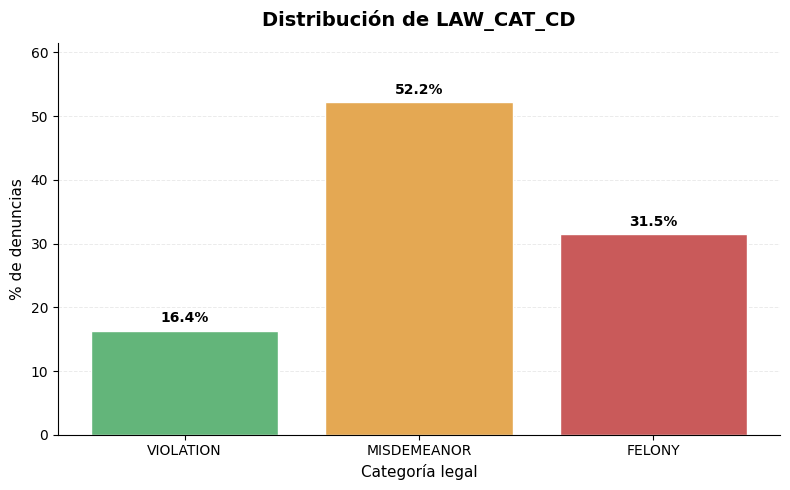

In [6]:
# ============================================================
# 6. DEFINICIÓN DEL TARGET Y ANÁLISIS DEL BALANCE DE CLASES
# ============================================================

# La variable objetivo representa la categoría legal asignada
# a cada denuncia registrada por el NYPD.

TARGET = "LAW_CAT_CD"

# Se fija explícitamente el orden de las clases desde la menor
# hasta la mayor severidad legal.

CLASES = [
    "VIOLATION",
    "MISDEMEANOR",
    "FELONY",
]


# Verificación temprana para evitar continuar si la variable
# objetivo no se encuentra disponible en el dataset.

if TARGET not in df.columns:
    raise ValueError(
        f"No se encontró la variable objetivo {TARGET!r}."
    )


# Se normalizan las etiquetas para evitar diferencias
# ocasionadas por espacios o uso inconsistente de mayúsculas.

df[TARGET] = (
    df[TARGET]
    .astype(str)
    .str.strip()
    .str.upper()
)


# Se conservan únicamente las tres categorías consideradas
# en el planteo del problema de clasificación.

df = (
    df[
        df[TARGET].isin(CLASES)
    ]
    .copy()
)


# Conteo absoluto de observaciones por clase.

conteos = (
    df[TARGET]
    .value_counts()
    .reindex(CLASES)
)


# Proporción relativa de cada clase.

proporciones = (
    conteos
    / conteos.sum()
)


# La entropía permite describir cuán distribuida se encuentra
# la variable objetivo entre las tres categorías.

entropia = -np.sum(
    proporciones
    * np.log2(proporciones)
)

entropia_max = np.log2(
    len(CLASES)
)


# El índice de Gini se utiliza como medida descriptiva
# complementaria de heterogeneidad.

gini = (
    1
    - np.sum(
        proporciones ** 2
    )
)


# Tabla resumen del balance de clases.

tabla_target = pd.DataFrame({
    "cantidad": conteos,
    "proporcion": proporciones,
    "porcentaje": proporciones * 100,
})


display(
    tabla_target.round({
        "proporcion": 4,
        "porcentaje": 2,
    })
)


print(
    f"Entropía: {entropia:.3f} "
    f"({entropia / entropia_max:.1%} del máximo)"
)

print(
    f"Gini: {gini:.3f}"
)


# Se asignan colores de acuerdo con la severidad legal:
# verde para VIOLATION, ámbar para MISDEMEANOR
# y rojo para FELONY.

colores_gravedad = {
    "VIOLATION": "#63B57A",
    "MISDEMEANOR": "#E4A853",
    "FELONY": "#C95A5A",
}

colores_barras = [
    colores_gravedad[clase]
    for clase in tabla_target.index
]


# Gráfico de distribución de la variable objetivo.

fig, ax = plt.subplots(
    figsize=(8, 5)
)

barras = ax.bar(
    tabla_target.index,
    tabla_target["porcentaje"],
    color=colores_barras,
    edgecolor="white",
    linewidth=1,
)


ax.set_ylabel(
    "% de denuncias",
    fontsize=11,
)

ax.set_xlabel(
    "Categoría legal",
    fontsize=11,
)

ax.set_title(
    "Distribución de LAW_CAT_CD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)


# Se reserva espacio superior para que las etiquetas
# permanezcan dentro del área del gráfico.

max_porcentaje = (
    tabla_target["porcentaje"].max()
)

ax.set_ylim(
    0,
    max_porcentaje * 1.18,
)


# Se muestra el porcentaje sobre cada barra.

for barra, valor in zip(
    barras,
    tabla_target["porcentaje"],
):

    ax.text(
        barra.get_x()
        + barra.get_width() / 2,
        valor + 0.8,
        f"{valor:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )


# Grilla horizontal suave para facilitar la lectura.

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.25,
)

ax.set_axisbelow(True)


# Se eliminan bordes superiores y derechos para
# obtener una visualización más limpia.

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

## 6.1 Estrategia frente al desbalance

No se aplicará *undersampling*, *oversampling* ni SMOTE. El desbalance es moderado y el TP previo mostró que estas técnicas introducen costos o supuestos difíciles de justificar.

En su lugar:

- usamos F1 macro y balanced accuracy;
- mantenemos la distribución real;
- utilizamos `class_weight="balanced"` cuando el algoritmo lo soporta.

# 7. Control de *data leakage*

`PD_CD`, `PD_DESC`, `KY_CD` y `OFNS_DESC` describen el delito con un nivel de detalle muy cercano al target. Si una categoría de esas columnas apunta casi siempre a una única clase legal, incluirla haría circular el problema.

In [7]:
# ============================================================
# CONTROL EMPÍRICO DE DATA LEAKAGE
# ============================================================

# Variables excluidas porque codifican de forma directa o casi directa
# información asociada a la categoría legal que se intenta predecir.

LEAKAGE_COLS = ["PD_CD", "PD_DESC", "KY_CD", "OFNS_DESC"]

# Para cada variable disponible se mide cuántas categorías aparecen
# asociadas a una única clase del target.
for columna in [c for c in ["PD_CD", "KY_CD", "OFNS_DESC"] if c in df.columns]:
    clases_por_categoria = df.groupby(columna, dropna=False)[TARGET].nunique()

    n_total = len(clases_por_categoria)
    n_univocas = (clases_por_categoria == 1).sum()

    print(
        f"{columna}: {n_univocas:,}/{n_total:,} categorías "
        f"({n_univocas/n_total:.1%}) aparecen asociadas "
        f"a una única clase de {TARGET}."
    )

PD_CD: 357/357 categorías (100.0%) aparecen asociadas a una única clase de LAW_CAT_CD.
KY_CD: 63/66 categorías (95.5%) aparecen asociadas a una única clase de LAW_CAT_CD.
OFNS_DESC: 42/55 categorías (76.4%) aparecen asociadas a una única clase de LAW_CAT_CD.


## Decisión

Las cuatro variables de leakage quedan fuera de todos los modelos. También se excluye `CMPLNT_NUM` porque es un identificador, no una característica explicativa.

La investigación se vuelve más difícil, pero las métricas pasan a tener un significado mucho más defendible.

# 8. Limpieza determinística

Separamos dos tipos de operaciones:

- **determinísticas:** parseo de fechas, coordenadas, fechas imposibles, variables temporales;
- **aprendidas:** escalado, One-Hot y Frequency Encoding.

Las transformaciones aprendidas se colocarán dentro del `Pipeline`, de modo que cada fold de validación ajuste sus propios parámetros.

In [10]:
# ============================================================
# 8. LIMPIEZA DETERMINÍSTICA
# ============================================================

# ------------------------------------------------------------
# Conversión robusta de fechas
# ------------------------------------------------------------

def parsear_fecha(serie):
    """
    Convierte una serie a datetime tolerando formatos mixtos.

    Se intenta primero con format="mixed", disponible en versiones
    recientes de pandas. Si no fuera compatible, se utiliza el
    parseo automático tradicional.
    """
    try:
        return pd.to_datetime(
            serie,
            format="mixed",
            errors="coerce",
        )

    except (TypeError, ValueError):

        return pd.to_datetime(
            serie,
            errors="coerce",
        )


# ------------------------------------------------------------
# Conversión robusta de variables numéricas
# ------------------------------------------------------------

def a_numerico_robusto(serie):
    """
    Convierte una serie a valores numéricos.

    También reemplaza comas decimales por puntos antes de
    realizar la conversión.
    """
    return pd.to_numeric(
        serie
        .astype(str)
        .str.replace(
            ",",
            ".",
            regex=False,
        ),
        errors="coerce",
    )


# ------------------------------------------------------------
# Función principal de limpieza
# ------------------------------------------------------------

def limpieza_deterministica(data):
    """
    Aplica transformaciones determinísticas necesarias
    antes del modelado.

    Estas operaciones no aprenden parámetros a partir de
    los datos, por lo que pueden realizarse antes del Pipeline.
    """

    data = data.copy()


    # --------------------------------------------------------
    # Fechas
    # --------------------------------------------------------

    for col in [
        "CMPLNT_FR_DT",
        "RPT_DT",
    ]:

        if col in data.columns:

            data[col] = parsear_fecha(
                data[col]
            )


    # --------------------------------------------------------
    # Coordenadas
    # --------------------------------------------------------

    for col in [
        "LATITUDE",
        "LONGITUDE",
    ]:

        if col in data.columns:

            data[col] = a_numerico_robusto(
                data[col]
            )


    # Las coordenadas iguales a cero no representan
    # ubicaciones válidas dentro del área analizada.
    if {
        "LATITUDE",
        "LONGITUDE",
    }.issubset(data.columns):

        coordenada_cero = (
            (data["LATITUDE"] == 0)
            | (data["LONGITUDE"] == 0)
        )

        data.loc[
            coordenada_cero,
            [
                "LATITUDE",
                "LONGITUDE",
            ],
        ] = np.nan


    # --------------------------------------------------------
    # Corrección de años evidentemente imposibles
    # --------------------------------------------------------

    if "CMPLNT_FR_DT" in data.columns:

        mask_anio_imposible = (
            data[
                "CMPLNT_FR_DT"
            ].dt.year
            < 1900
        )


        def corregir_anio(fecha):
            """
            Corrige años del tipo 1026 → 2026.

            La corrección solamente se conserva si produce
            una demora temporal plausible respecto de RPT_DT.
            """
            nuevo_anio = int(
                "2"
                + str(
                    fecha.year
                )[1:]
            )

            return fecha.replace(
                year=nuevo_anio
            )


        candidatas = (
            data.loc[
                mask_anio_imposible,
                "CMPLNT_FR_DT",
            ]
            .apply(
                corregir_anio
            )
        )


        # ----------------------------------------------------
        # Validación de la corrección mediante demora
        # ----------------------------------------------------

        demora_si_corrijo = (
            data.loc[
                mask_anio_imposible,
                "RPT_DT",
            ]
            - candidatas
        ).dt.days


        sin_evidencia = (
            (demora_si_corrijo < 0)
            | (demora_si_corrijo > 1000)
        )


        idx_corregir = (
            candidatas[
                ~sin_evidencia
            ].index
        )

        idx_invalidar = (
            candidatas[
                sin_evidencia
            ].index
        )


        # Se conservan solamente las correcciones plausibles.
        data.loc[
            idx_corregir,
            "CMPLNT_FR_DT",
        ] = candidatas.loc[
            idx_corregir
        ]


        # Las fechas que no pueden corregirse de forma
        # justificable se consideran valores faltantes.
        data.loc[
            idx_invalidar,
            "CMPLNT_FR_DT",
        ] = pd.NaT


        # ----------------------------------------------------
        # Eliminación de fecha Unix epoch
        # ----------------------------------------------------

        mask_epoch = (
            data[
                "CMPLNT_FR_DT"
            ]
            == pd.Timestamp(
                "1970-01-01"
            )
        )

        data.loc[
            mask_epoch,
            "CMPLNT_FR_DT",
        ] = pd.NaT


    # --------------------------------------------------------
    # Demoras negativas
    # --------------------------------------------------------

    demora_preliminar = (
        data["RPT_DT"]
        - data["CMPLNT_FR_DT"]
    ).dt.days


    idx_negativos = (
        demora_preliminar[
            demora_preliminar < 0
        ].index
    )


    # Una fecha de ocurrencia posterior a la fecha de reporte
    # no es temporalmente válida para este análisis.
    data.loc[
        idx_negativos,
        "CMPLNT_FR_DT",
    ] = pd.NaT


    # --------------------------------------------------------
    # Variables temporales derivadas
    # --------------------------------------------------------

    data[
        "CMPLNT_FR_MONTH"
    ] = (
        data[
            "CMPLNT_FR_DT"
        ].dt.month
    )


    data[
        "CMPLNT_FR_DOW"
    ] = (
        data[
            "CMPLNT_FR_DT"
        ].dt.dayofweek
    )


    data[
        "CMPLNT_FR_HOUR"
    ] = pd.to_datetime(
        data[
            "CMPLNT_FR_TM"
        ],
        format="%H:%M:%S",
        errors="coerce",
    ).dt.hour


    # --------------------------------------------------------
    # Demora entre ocurrencia y reporte
    # --------------------------------------------------------

    data[
        "DEMORA_REPORTE_DIAS"
    ] = (
        data["RPT_DT"]
        - data["CMPLNT_FR_DT"]
    ).dt.days


    return data


# ============================================================
# APLICACIÓN DE LA LIMPIEZA
# ============================================================

df_ml = limpieza_deterministica(
    df
)


# ------------------------------------------------------------
# Controles posteriores
# ------------------------------------------------------------

print(
    "Años imposibles restantes:",
    int(
        (
            df_ml[
                "CMPLNT_FR_DT"
            ].dt.year
            < 1900
        ).sum()
    ),
)

print(
    "Demoras negativas restantes:",
    int(
        (
            df_ml[
                "DEMORA_REPORTE_DIAS"
            ]
            < 0
        ).sum()
    ),
)

print(
    "Limpieza determinística completada.")


Años imposibles restantes: 0
Demoras negativas restantes: 0
Limpieza determinística completada.


# 9. Selección del espacio de predictores

Se excluyen variables sensibles de víctima y sospechoso, además de variables redundantes o cercanas al target. El objetivo es trabajar con contexto temporal, geográfico y del lugar del hecho.

In [16]:
# ============================================================
# DEFINICIÓN DEL ESPACIO DE PREDICTORES
# ============================================================

# Conjunto contextual utilizado por el modelo principal. Se excluyen
# deliberadamente las variables identificadas como leakage.

PREDICTORES = [
    "LATITUDE",
    "LONGITUDE",
    "DEMORA_REPORTE_DIAS",
    "CMPLNT_FR_MONTH",
    "CMPLNT_FR_DOW",
    "CMPLNT_FR_HOUR",
    "CRM_ATPT_CPTD_CD",
    "LOC_OF_OCCUR_DESC",
    "PREM_TYP_DESC",
    "HADEVELOPT",
    "STATION_NAME",
    "PARKS_NM",
    "HOUSING_PSA",
    "TRANSIT_DISTRICT",
    "JURIS_DESC",
]

# Verificación de que todas las columnas esperadas estén disponibles.
faltantes_predictores = [c for c in PREDICTORES if c not in df_ml.columns]

if faltantes_predictores:
    raise ValueError(f"Faltan columnas esperadas: {faltantes_predictores}")

# Variables indispensables para construir una observación válida.
CRITICAS = [
    TARGET,
    "LATITUDE",
    "LONGITUDE",
    "CMPLNT_FR_MONTH",
    "CMPLNT_FR_DOW",
    "CMPLNT_FR_HOUR",
    "DEMORA_REPORTE_DIAS",
]

# Se eliminan únicamente filas con faltantes en variables críticas.
n_antes = len(df_ml)
df_ml = df_ml.dropna(subset=CRITICAS).copy()
n_despues = len(df_ml)

print(f"Filas antes del filtro crítico: {n_antes:,}")
print(f"Filas para modelado:           {n_despues:,}")
print(
    f"Eliminadas:                    {n_antes-n_despues:,} "
    f"({(n_antes-n_despues)/n_antes:.3%})"
)

# Matriz de predictores y vector objetivo definitivos.
X = df_ml[PREDICTORES].copy()
y = df_ml[TARGET].copy()

Filas antes del filtro crítico: 279,495
Filas para modelado:           279,495
Eliminadas:                    0 (0.000%)


# 10. Split train/test

Test se separa antes de cualquier transformación aprendida y no participa de la selección de modelos ni de hiperparámetros.

In [17]:
#=============================================================
# PARTICIÓN TRAIN / TEST
# ============================================================

# Se reserva test antes de cualquier selección o ajuste de modelos.
# La estratificación conserva aproximadamente la proporción de clases.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train: {len(X_train):,}")
print(f"Test:  {len(X_test):,}")

# Comparación de proporciones para comprobar que el split quedó estratificado.
tabla_split = pd.DataFrame({
    "train_%": (
        y_train.value_counts(normalize=True).reindex(CLASES) * 100
    ).round(2),
    "test_%": (
        y_test.value_counts(normalize=True).reindex(CLASES) * 100
    ).round(2),
})

display(tabla_split)

# Control de independencia entre índices de train y test.
assert set(X_train.index).isdisjoint(set(X_test.index))

Train: 223,596
Test:  55,899


,train_%,test_%
LAW_CAT_CD,,
VIOLATION,16.36,16.36
MISDEMEANOR,52.15,52.15
FELONY,31.49,31.49


# 11. Preprocesamiento dentro del `Pipeline`

El preprocesamiento se implementa dentro de un `Pipeline` de *scikit-learn* para garantizar que todos los parámetros de transformación se aprendan exclusivamente a partir de los datos de entrenamiento de cada partición.

## Tratamiento de variables categóricas

`PREM_TYP_DESC` describe el tipo de lugar asociado al hecho y contiene información categórica relevante. Para preservar la identidad de sus categorías sin generar una expansión excesiva de dimensionalidad, se adopta la siguiente estrategia:

- se conservan explícitamente las 20 categorías más frecuentes;
- las categorías restantes se agrupan bajo la etiqueta `OTRO`;
- posteriormente se aplica *One-Hot Encoding*.

`LOC_OF_OCCUR_DESC`, por presentar baja cardinalidad, también se representa mediante *One-Hot Encoding*.

Para las variables categóricas de mayor cardinalidad restantes se utiliza *Frequency Encoding*, con el objetivo de mantener una representación compacta.

## Prevención de *data leakage* durante la validación cruzada

El transformador forma parte de cada `Pipeline`. Por lo tanto, en cada *fold* de validación cruzada:

1. las categorías principales de `PREM_TYP_DESC` se determinan únicamente sobre el subconjunto de entrenamiento;
2. las frecuencias de las variables categóricas se calculan exclusivamente sobre ese subconjunto;
3. el codificador *One-Hot* aprende sus categorías solo a partir del entrenamiento;
4. los escaladores y valores utilizados para imputación se ajustan sin utilizar el conjunto de validación.

De esta manera, la información del *fold* de validación no interviene en el aprendizaje del preprocesamiento.

In [18]:
# ============================================================
# 11. PREPROCESAMIENTO DENTRO DEL PIPELINE
# ============================================================

# El transformador aprende todos los parámetros de preprocesamiento
# exclusivamente a partir de los datos recibidos en fit().
#
# Esto permite incluirlo dentro del Pipeline y evita que información
# del conjunto de validación intervenga en:
#
# - selección de categorías frecuentes;
# - Frequency Encoding;
# - One-Hot Encoding;
# - escalado;
# - imputación.
#
# PREM_TYP_DESC recibe un tratamiento especial: se conservan las
# categorías más frecuentes y las restantes se agrupan como OTRO.


class NYPDFeatureTransformer(
    TransformerMixin,
    BaseEstimator,
):
    """
    Transforma variables contextuales crudas en una matriz numérica.

    Principios:
    - fit() aprende parámetros únicamente del conjunto recibido;
    - PREM_TYP_DESC conserva identidad con One-Hot top-N + OTRO;
    - variables de cardinalidad alta restantes usan Frequency Encoding;
    - hora, mes y día se representan de forma cíclica;
    - escalado e imputaciones se aprenden solo en fit().
    """

    # Cantidad de categorías de premisa que conservamos explícitamente.
    TOP_N_PREMISAS = 20


    # ------------------------------------------------------------
    # Valores estructurales
    # ------------------------------------------------------------

    # En estas variables, un valor ausente puede interpretarse como
    # que la característica no resulta aplicable al registro.

    ESTRUCTURALES = {
        "HADEVELOPT": "NO_APLICA",
        "STATION_NAME": "NO_APLICA",
        "PARKS_NM": "NO_APLICA",
        "HOUSING_PSA": "NO_APLICA",
        "TRANSIT_DISTRICT": "NO_APLICA",
    }


    # ------------------------------------------------------------
    # Valores categóricos no especificados
    # ------------------------------------------------------------

    # En estas variables, la ausencia se conserva como una categoría
    # explícita en lugar de eliminar la observación.

    NO_ESPECIFICADAS = {
        "LOC_OF_OCCUR_DESC": "NO_ESPECIFICADO",
        "PREM_TYP_DESC": "NO_ESPECIFICADO",
        "JURIS_DESC": "NO_ESPECIFICADO",
    }


    # ------------------------------------------------------------
    # Variables de alta cardinalidad
    # ------------------------------------------------------------

    # PREM_TYP_DESC sale deliberadamente de este grupo porque
    # se representa mediante One-Hot Encoding top-N + OTRO.

    FREQ_COLS = (
        "HADEVELOPT",
        "STATION_NAME",
        "PARKS_NM",
        "HOUSING_PSA",
        "TRANSIT_DISTRICT",
        "JURIS_DESC",
    )


    # ------------------------------------------------------------
    # Variables representadas mediante One-Hot Encoding
    # ------------------------------------------------------------

    ONEHOT_COLS = (
        "LOC_OF_OCCUR_DESC",
        "PREM_TYP_DESC",
    )


    # ============================================================
    # NORMALIZACIÓN DE VARIABLES CATEGÓRICAS
    # ============================================================

    def _normalizar_categoricas(
        self,
        X,
    ):
        """
        Normaliza valores faltantes de las variables categóricas.

        La transformación es determinística y no aprende parámetros.
        """

        X = X.copy()


        # --------------------------------------------------------
        # Variables estructurales
        # --------------------------------------------------------

        for col, valor in self.ESTRUCTURALES.items():

            if col in X.columns:

                X[col] = (
                    X[col]
                    .astype("object")
                    .fillna(valor)
                    .astype(str)
                )


        # --------------------------------------------------------
        # Variables no especificadas
        # --------------------------------------------------------

        for col, valor in self.NO_ESPECIFICADAS.items():

            if col in X.columns:

                X[col] = (
                    X[col]
                    .astype("object")
                    .fillna(valor)
                    .astype(str)
                )


        return X


    # ============================================================
    # AGRUPACIÓN DE PREMISAS
    # ============================================================

    def _agrupar_premisas(
        self,
        X,
    ):
        """
        Conserva las categorías frecuentes aprendidas en fit()
        y agrupa cualquier otra como OTRO.
        """

        X = X.copy()


        if "PREM_TYP_DESC" in X.columns:

            X["PREM_TYP_DESC"] = (
                X["PREM_TYP_DESC"]
                .where(
                    X["PREM_TYP_DESC"].isin(
                        self.premisas_top_
                    ),
                    "OTRO",
                )
            )


        return X


    # ============================================================
    # FIT
    # ============================================================

    def fit(
        self,
        X,
        y=None,
    ):
        """
        Aprende todos los parámetros necesarios para transformar
        posteriormente observaciones nuevas.

        Ningún parámetro se calcula fuera del conjunto recibido
        por este método.
        """

        X = self._normalizar_categoricas(
            X
        )


        # --------------------------------------------------------
        # A) PREM_TYP_DESC:
        # categorías principales del subconjunto de entrenamiento
        # --------------------------------------------------------

        if "PREM_TYP_DESC" in X.columns:

            conteo_premisas = (
                X["PREM_TYP_DESC"]
                .value_counts()
            )

            self.premisas_top_ = set(
                conteo_premisas
                .head(
                    self.TOP_N_PREMISAS
                )
                .index
            )

        else:

            self.premisas_top_ = set()


        # Se genera una copia con las categorías poco frecuentes
        # agrupadas como OTRO.

        X_ohe = self._agrupar_premisas(
            X
        )


        # --------------------------------------------------------
        # B) Intento / completado
        # --------------------------------------------------------

        mapa = {
            "COMPLETED": 1.0,
            "ATTEMPTED": 0.0,
        }


        crm_train = (
            X["CRM_ATPT_CPTD_CD"]
            .astype(str)
            .str.upper()
            .map(mapa)
        )


        # Si todos los valores fueran faltantes se utiliza 1.0.
        # En caso contrario se aprende la moda del conjunto de fit.

        self.crm_fill_ = (
            1.0
            if crm_train.dropna().empty
            else float(
                crm_train
                .mode()
                .iloc[0]
            )
        )


        # --------------------------------------------------------
        # C) Frequency Encoding para alta cardinalidad restante
        # --------------------------------------------------------

        self.freq_cols_ = [
            col
            for col in self.FREQ_COLS
            if col in X.columns
        ]


        # Para cada categoría se aprende su frecuencia relativa
        # únicamente sobre el conjunto recibido por fit().

        self.freq_maps_ = {
            col: (
                X[col]
                .astype(str)
                .value_counts(
                    normalize=True
                )
            )
            for col in self.freq_cols_
        }


        # --------------------------------------------------------
        # D) One-Hot Encoding
        # --------------------------------------------------------

        self.onehot_cols_ = [
            col
            for col in self.ONEHOT_COLS
            if col in X_ohe.columns
        ]


        # Compatibilidad con versiones nuevas y antiguas
        # de scikit-learn.

        try:

            self.ohe_ = OneHotEncoder(
                sparse_output=False,
                handle_unknown="ignore",
            )

        except TypeError:

            self.ohe_ = OneHotEncoder(
                sparse=False,
                handle_unknown="ignore",
            )


        if self.onehot_cols_:

            self.ohe_.fit(
                X_ohe[
                    self.onehot_cols_
                ]
            )


        # --------------------------------------------------------
        # E) Coordenadas geográficas
        # --------------------------------------------------------

        self.geo_scaler_ = (
            MinMaxScaler()
        )


        self.geo_scaler_.fit(
            X[
                [
                    "LATITUDE",
                    "LONGITUDE",
                ]
            ].astype(float)
        )


        # --------------------------------------------------------
        # F) Demora de reporte:
        # transformación logarítmica + estandarización
        # --------------------------------------------------------

        demora_log = np.log1p(
            X[
                "DEMORA_REPORTE_DIAS"
            ]
            .astype(float)
            .clip(lower=0)
            .to_numpy()
            .reshape(-1, 1)
        )


        self.demora_scaler_ = (
            StandardScaler()
        )


        self.demora_scaler_.fit(
            demora_log
        )


        # --------------------------------------------------------
        # G) Estructura final de la matriz
        # --------------------------------------------------------

        # Se construye una primera matriz transformada para fijar
        # el orden definitivo de las columnas.

        matriz = self._transform_core(
            X
        )


        self.feature_names_out_ = list(
            matriz.columns
        )


        # Las medianas se aprenden solamente sobre el conjunto
        # utilizado en fit(). Luego se emplean para imputar valores
        # residuales durante transform().

        self.medians_ = matriz.median(
            numeric_only=True
        )


        return self


    # ============================================================
    # TRANSFORMACIÓN INTERNA
    # ============================================================

    def _transform_core(
        self,
        X,
    ):
        """
        Construye la matriz numérica utilizando exclusivamente
        los parámetros aprendidos previamente en fit().
        """

        X = self._normalizar_categoricas(
            X
        )


        X_ohe = self._agrupar_premisas(
            X
        )


        partes = []


        # --------------------------------------------------------
        # Geografía
        # --------------------------------------------------------

        geo = pd.DataFrame(
            self.geo_scaler_.transform(
                X[
                    [
                        "LATITUDE",
                        "LONGITUDE",
                    ]
                ].astype(float)
            ),
            columns=[
                "LATITUDE_MM",
                "LONGITUDE_MM",
            ],
            index=X.index,
        )


        partes.append(
            geo
        )


        # --------------------------------------------------------
        # Demora de reporte
        # --------------------------------------------------------

        demora_log = np.log1p(
            X[
                "DEMORA_REPORTE_DIAS"
            ]
            .astype(float)
            .clip(lower=0)
            .to_numpy()
            .reshape(-1, 1)
        )


        demora_std = pd.DataFrame(
            self.demora_scaler_.transform(
                demora_log
            ),
            columns=[
                "DEMORA_REPORTE_LOG_Z"
            ],
            index=X.index,
        )


        partes.append(
            demora_std
        )


        # --------------------------------------------------------
        # Variables temporales cíclicas
        # --------------------------------------------------------

        # Mes, hora y día de la semana poseen naturaleza circular.
        # La representación seno/coseno evita interpretar, por ejemplo,
        # diciembre y enero como extremos alejados.

        temporales = pd.DataFrame(
            {
                "MONTH_SIN": np.sin(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_MONTH"
                    ].astype(float)
                    / 12
                ),

                "MONTH_COS": np.cos(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_MONTH"
                    ].astype(float)
                    / 12
                ),

                "HOUR_SIN": np.sin(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_HOUR"
                    ].astype(float)
                    / 24
                ),

                "HOUR_COS": np.cos(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_HOUR"
                    ].astype(float)
                    / 24
                ),

                "DOW_SIN": np.sin(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_DOW"
                    ].astype(float)
                    / 7
                ),

                "DOW_COS": np.cos(
                    2
                    * np.pi
                    * X[
                        "CMPLNT_FR_DOW"
                    ].astype(float)
                    / 7
                ),
            },
            index=X.index,
        )


        partes.append(
            temporales
        )


        # --------------------------------------------------------
        # Intento / completado
        # --------------------------------------------------------

        crm = (
            X[
                "CRM_ATPT_CPTD_CD"
            ]
            .astype(str)
            .str.upper()
            .map(
                {
                    "COMPLETED": 1.0,
                    "ATTEMPTED": 0.0,
                }
            )
            .fillna(
                self.crm_fill_
            )
            .astype(float)
            .rename(
                "CRM_COMPLETED"
            )
            .to_frame()
        )


        partes.append(
            crm
        )


        # --------------------------------------------------------
        # Frequency Encoding
        # --------------------------------------------------------

        freq_df = pd.DataFrame(
            index=X.index
        )


        for col in self.freq_cols_:

            freq_df[
                f"{col}_FREQ"
            ] = (
                X[col]
                .astype(str)
                .map(
                    self.freq_maps_[col]
                )
                .fillna(0.0)
                .astype(float)
            )


        partes.append(
            freq_df
        )


        # --------------------------------------------------------
        # One-Hot Encoding:
        # LOC_OF_OCCUR_DESC + PREM_TYP_DESC top-N / OTRO
        # --------------------------------------------------------

        if self.onehot_cols_:

            ohe_array = (
                self.ohe_
                .transform(
                    X_ohe[
                        self.onehot_cols_
                    ]
                )
            )


            ohe_df = pd.DataFrame(
                ohe_array,
                columns=(
                    self.ohe_
                    .get_feature_names_out(
                        self.onehot_cols_
                    )
                ),
                index=X.index,
            )


            partes.append(
                ohe_df
            )


        # Se concatenan todas las representaciones en una única
        # matriz numérica.

        return pd.concat(
            partes,
            axis=1,
        )


    # ============================================================
    # TRANSFORM
    # ============================================================

    def transform(
        self,
        X,
    ):
        """
        Aplica a nuevas observaciones exactamente las transformaciones
        aprendidas durante fit().
        """

        matriz = self._transform_core(
            X
        )


        # Se garantiza que train, validación y test posean exactamente
        # las mismas columnas y en el mismo orden.

        matriz = matriz.reindex(
            columns=self.feature_names_out_,
            fill_value=0.0,
        )


        # Los faltantes residuales se completan con medianas aprendidas
        # en fit(). Si todavía quedara algún NaN, se reemplaza por cero.

        return (
            matriz
            .fillna(
                self.medians_
            )
            .fillna(0.0)
            .astype(float)
        )


    # ============================================================
    # NOMBRES DE FEATURES RESULTANTES
    # ============================================================

    def get_feature_names_out(
        self,
        input_features=None,
    ):
        """
        Devuelve los nombres de las variables generadas por
        el transformador.
        """

        return np.array(
            self.feature_names_out_,
            dtype=object,
        )


# ============================================================
# VERIFICACIÓN DE LA DEFINICIÓN
# ============================================================

print(
    "NYPDFeatureTransformer definido correctamente."
)

print(
    "El transformador todavía no fue ajustado a los datos."
)

NYPDFeatureTransformer definido correctamente.
El transformador todavía no fue ajustado a los datos.


## 11.1 Inspección del preprocesamiento

Ajustamos una copia del transformador sobre `train` únicamente para documentar:

- cuántas features finales produce;
- cuáles son las 20 categorías de `PREM_TYP_DESC` que conservan identidad;
- que el resto queda agrupado como `OTRO`.

Los pipelines de validación cruzada no reutilizan este objeto: cada fold aprende sus propias categorías principales.

In [19]:
# ============================================================
# INSPECCIÓN DEL PREPROCESAMIENTO
# ============================================================

# Se ajusta una instancia solo con fines de inspección.
# Los pipelines de CV crean sus propios transformadores dentro de cada fold.

prep_demo = (
    NYPDFeatureTransformer()
)

prep_demo.fit(
    X_train
)

# Transformación de unas pocas filas para verificar la estructura de salida.
X_demo = prep_demo.transform(
    X_train.head(5)
)

print(
    "Features finales:",
    len(
        prep_demo
        .get_feature_names_out()
    ),
)

print(
    "\nPREM_TYP_DESC conservadas explícitamente:"
)

# Categorías de PREM_TYP_DESC que conservan identidad propia.
for categoria in sorted(
    prep_demo.premisas_top_
):
    print(
        " -",
        categoria,
    )

print(
    "\nTodas las demás categorías se agrupan como OTRO."
)

display(
    X_demo
)

Features finales: 43

PREM_TYP_DESC conservadas explícitamente:
 - BAR/NIGHT CLUB
 - CHAIN STORE
 - CLOTHING/BOUTIQUE
 - COMMERCIAL BUILDING
 - DEPARTMENT STORE
 - DRUG STORE
 - FAST FOOD
 - FOOD SUPERMARKET
 - GROCERY/BODEGA
 - HOMELESS SHELTER
 - HOTEL/MOTEL
 - OTHER
 - PARK/PLAYGROUND
 - PUBLIC SCHOOL
 - RESIDENCE - APT. HOUSE
 - RESIDENCE - PUBLIC HOUSING
 - RESIDENCE-HOUSE
 - RESTAURANT/DINER
 - STREET
 - TRANSIT - NYC SUBWAY

Todas las demás categorías se agrupan como OTRO.


,LATITUDE_MM,LONGITUDE_MM,DEMORA_REPORTE_LOG_Z,MONTH_SIN,MONTH_COS,HOUR_SIN,HOUR_COS,DOW_SIN,DOW_COS,CRM_COMPLETED,HADEVELOPT_FREQ,STATION_NAME_FREQ,PARKS_NM_FREQ,HOUSING_PSA_FREQ,TRANSIT_DISTRICT_FREQ,JURIS_DESC_FREQ,LOC_OF_OCCUR_DESC_FRONT OF,LOC_OF_OCCUR_DESC_INSIDE,LOC_OF_OCCUR_DESC_NO_ESPECIFICADO,LOC_OF_OCCUR_DESC_OPPOSITE OF,LOC_OF_OCCUR_DESC_OUTSIDE,LOC_OF_OCCUR_DESC_REAR OF,PREM_TYP_DESC_BAR/NIGHT CLUB,PREM_TYP_DESC_CHAIN STORE,PREM_TYP_DESC_CLOTHING/BOUTIQUE,PREM_TYP_DESC_COMMERCIAL BUILDING,PREM_TYP_DESC_DEPARTMENT STORE,PREM_TYP_DESC_DRUG STORE,PREM_TYP_DESC_FAST FOOD,PREM_TYP_DESC_FOOD SUPERMARKET,PREM_TYP_DESC_GROCERY/BODEGA,PREM_TYP_DESC_HOMELESS SHELTER,PREM_TYP_DESC_HOTEL/MOTEL,PREM_TYP_DESC_OTHER,PREM_TYP_DESC_OTRO,PREM_TYP_DESC_PARK/PLAYGROUND,PREM_TYP_DESC_PUBLIC SCHOOL,PREM_TYP_DESC_RESIDENCE - APT. HOUSE,PREM_TYP_DESC_RESIDENCE - PUBLIC HOUSING,PREM_TYP_DESC_RESIDENCE-HOUSE,PREM_TYP_DESC_RESTAURANT/DINER,PREM_TYP_DESC_STREET,PREM_TYP_DESC_TRANSIT - NYC SUBWAY
128800,0.537094,0.496288,0.441534,0.5,-8.660254e-01,-0.866025,-0.500000,0.000000,1.000000,1.0,0.996722,0.936578,0.995,0.934458,0.936578,0.858499,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
232345,0.816442,0.664934,0.106225,0.5,8.660254e-01,0.258819,0.965926,0.433884,-0.900969,1.0,0.996722,0.936578,0.995,0.934458,0.936578,0.858499,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4304,0.225689,0.559825,2.784527,0.5,-8.660254e-01,-0.500000,0.866025,0.000000,1.000000,1.0,0.996722,0.936578,0.995,0.934458,0.936578,0.858499,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13419,0.290858,0.483393,-0.466990,1.0,6.123234e-17,-0.500000,-0.866025,-0.781831,0.623490,1.0,0.996722,0.936578,0.995,0.934458,0.936578,0.858499,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
161661,0.604510,0.470190,-0.466990,1.0,6.123234e-17,0.707107,-0.707107,-0.974928,-0.222521,1.0,0.996722,0.936578,0.995,0.934458,0.936578,0.858499,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# 12. Baselines

Usamos dos baselines porque “superar a la clase mayoritaria” es una vara demasiado baja.

## 12.1 Baseline trivial
`DummyClassifier(strategy="most_frequent")`: siempre predice la clase más frecuente.

## 12.2 Baseline contextual
Para cada `PREM_TYP_DESC`, predice la clase modal observada en train. Si aparece una categoría nueva, utiliza la clase global modal.

Este segundo baseline es deliberadamente simple, interpretable y contextual.

In [20]:
# ============================================================
# BASELINE CONTEXTUAL POR TIPO DE PREMISA
# ============================================================

# Predice, para cada tipo de premisa, la clase modal observada en train.
# Las categorías no vistas utilizan la moda global de entrenamiento.

class PremiseModeBaseline(ClassifierMixin, BaseEstimator):
    def __init__(self, column="PREM_TYP_DESC"):
        self.column = column

    def fit(self, X, y):
        # Aprende el mapeo categoría -> clase modal usando solo train.
        if self.column not in X.columns:
            raise ValueError(f"No existe {self.column}")

        serie_x = (
            X[self.column]
            .astype("object")
            .fillna("NO_ESPECIFICADO")
            .astype(str)
        )

        serie_y = pd.Series(
            np.asarray(y),
            index=X.index,
            name="target",
        )

        base = pd.DataFrame({
            "categoria": serie_x,
            "target": serie_y,
        })

        self.global_mode_ = serie_y.mode().iloc[0]

        self.mapping_ = (
            base
            .groupby("categoria")["target"]
            .agg(lambda s: s.value_counts().index[0])
            .to_dict()
        )

        self.classes_ = np.array(
            sorted(serie_y.unique()),
            dtype=object,
        )

        return self

    def predict(self, X):
        # Aplica el mapeo aprendido; categorías nuevas usan la moda global.
        categorias = (
            X[self.column]
            .astype("object")
            .fillna("NO_ESPECIFICADO")
            .astype(str)
        )

        return np.array([
            self.mapping_.get(categoria, self.global_mode_)
            for categoria in categorias
        ])

# 13. Qué algoritmos se comparan y por qué

Cada modelo representa una hipótesis distinta.

## Regresión logística multinomial
Sirve como referencia lineal, escalable e interpretable.

## Árbol de decisión
Introduce relaciones no lineales e interacciones, pero puede sufrir alta varianza.

## Bagging
Promedia/vota muchos árboles entrenados sobre remuestreos bootstrap para reducir varianza.

## Random Forest
Extiende Bagging agregando aleatoriedad de atributos, con el objetivo de reducir correlación entre árboles.

## Gradient Boosting
Construye un ensamble secuencial en el que cada etapa intenta corregir errores de las anteriores.

La comparación no busca acumular algoritmos, sino observar qué complejidad está realmente justificada por los datos.

# 14. Opciones consideradas y no elegidas para la comparación principal

## KNN
Fue visto en la materia, pero su costo de inferencia crece con la cantidad de observaciones y la distancia sobre una mezcla de variables cíclicas, de frecuencia y dummies requiere decisiones adicionales.

## SVM con kernel
Es potente, pero puede resultar costoso con cientos de miles de observaciones. Los ejemplos docentes lo aplican en datasets mucho menores.

## Clustering
No corresponde al objetivo porque existe una variable respuesta conocida.

## PCA
Ya fue evaluado en el TP previo: reduce dimensionalidad, pero pierde interpretabilidad y no mostró una separación clara del target.

## XGBoost
Es una alternativa válida de Boosting. Se deja como extensión para no convertir el TP en una competencia interminable de implementaciones de la misma familia.

# 15. Construcción de candidatos

Todos los modelos aprendidos usan el mismo preprocesamiento dentro de un `Pipeline`, para que la comparación sea justa.

In [21]:
# ============================================================
# DEFINICIÓN DE PIPELINES Y MODELOS A COMPARAR
# ============================================================

def pipeline_con(modelo):
    """
    Construye un Pipeline que aplica primero el preprocesamiento
    y luego entrena el modelo recibido.
    """
    return Pipeline([
        ("prep", NYPDFeatureTransformer()),
        ("model", modelo),
    ])


# ------------------------------------------------------------
# Modelos y baselines
# ------------------------------------------------------------

modelos = {
    "Baseline_mayoritaria": DummyClassifier(
        strategy="most_frequent",
    ),

    "Baseline_premisa": PremiseModeBaseline(),

    "Regresion_logistica": pipeline_con(
        LogisticRegression(
            solver="lbfgs",
            max_iter=1500,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),

    "Arbol": pipeline_con(
        DecisionTreeClassifier(
            max_depth=18,
            min_samples_leaf=40,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),

    "Bagging": pipeline_con(
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                class_weight="balanced",
                min_samples_leaf=2,
                random_state=RANDOM_STATE,
            ),
            n_estimators=150,
            max_samples=0.8,
            bootstrap=True,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),

    "Random_Forest": pipeline_con(
        RandomForestClassifier(
            n_estimators=250,
            max_features="sqrt",
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),

    "Gradient_Boosting": pipeline_con(
        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=150,
            max_leaf_nodes=31,
            min_samples_leaf=30,
            l2_regularization=0.1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),
}


# ------------------------------------------------------------
# Verificación visual
# ------------------------------------------------------------

print("Modelos definidos para la comparación:")
print("-" * 45)

for nombre, modelo in modelos.items():
    print(f"• {nombre}")

print("-" * 45)
print(f"Total de modelos definidos: {len(modelos)}")
print(
    "\nNota: en esta celda solo se preparan los modelos. "
    "El entrenamiento se realiza en la etapa de validación cruzada."
)

Modelos definidos para la comparación:
---------------------------------------------
• Baseline_mayoritaria
• Baseline_premisa
• Regresion_logistica
• Arbol
• Bagging
• Random_Forest
• Gradient_Boosting
---------------------------------------------
Total de modelos definidos: 7

Nota: en esta celda solo se preparan los modelos. El entrenamiento se realiza en la etapa de validación cruzada.


# 16. Selección de modelos sin mirar test

La validación de todos los candidatos se hace sobre una muestra estratificada de train. Test permanece completamente cerrado.

La métrica principal es F1 macro, complementada con balanced accuracy, accuracy y tiempos.

In [22]:
# ============================================================
# SUBMUESTRA DE SELECCIÓN Y CONFIGURACIÓN DE CV
# ============================================================

# Para acotar el costo computacional, la comparación de familias se realiza
# sobre una muestra estratificada de train. Test permanece intacto.

if len(X_train) > N_MUESTRA_CV:
    X_select, _, y_select, _ = train_test_split(
        X_train,
        y_train,
        train_size=N_MUESTRA_CV,
        random_state=RANDOM_STATE,
        stratify=y_train,
    )
else:
    X_select = X_train.copy()
    y_select = y_train.copy()

print(f"Observaciones para selección: {len(X_select):,}")

# Esquema común de validación cruzada para todos los modelos.
CV = StratifiedKFold(
    n_splits=N_SPLITS_CV,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# F1 macro es la métrica principal; las demás son complementarias.
SCORING = {
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
}

Observaciones para selección: 50,000


## 16.1 Validación cruzada comparable

Todos los candidatos usan los mismos folds. Se reportan media y dispersión, porque una diferencia pequeña puede no ser relevante si queda dentro de la variabilidad entre folds.

In [23]:
# ============================================================
# 16.1 VALIDACIÓN CRUZADA COMPARABLE
# ============================================================

# Contenedor para guardar una fila de métricas por modelo.
filas_cv = []

print("Inicio de la validación cruzada")
print(f"Observaciones utilizadas: {len(X_select):,}")
print(f"Cantidad de folds: {N_SPLITS_CV}")
print(f"Modelos a evaluar: {len(modelos)}")
print("-" * 60)


# Todos los modelos usan el mismo subconjunto, folds y métricas.
for i, (nombre, estimador) in enumerate(
    modelos.items(),
    start=1,
):
    print()
    print(
        f"[{i}/{len(modelos)}] Evaluando: {nombre}"
    )

    inicio_modelo = time.perf_counter()

    # Entrenamiento y evaluación del estimador en cada fold.
    salida = cross_validate(
        estimator=estimador,
        X=X_select,
        y=y_select,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
    )

    fin_modelo = time.perf_counter()

    # Resumen de medias, dispersión y tiempos.
    fila = {
        "Modelo": nombre,
        "F1_macro_CV": salida[
            "test_f1_macro"
        ].mean(),
        "F1_macro_std": salida[
            "test_f1_macro"
        ].std(),
        "Balanced_accuracy_CV": salida[
            "test_balanced_accuracy"
        ].mean(),
        "Accuracy_CV": salida[
            "test_accuracy"
        ].mean(),
        "Fit_time_s": salida[
            "fit_time"
        ].mean(),
        "Score_time_s": salida[
            "score_time"
        ].mean(),
        "Tiempo_total_s": (
            fin_modelo - inicio_modelo
        ),
    }

    filas_cv.append(
        fila
    )

    # Se reconstruye la tabla después de cada modelo
    # para que quede disponible incluso durante la corrida.
    tabla_cv = (
        pd.DataFrame(
            filas_cv
        )
        .set_index(
            "Modelo"
        )
        .sort_values(
            "F1_macro_CV",
            ascending=False,
        )
    )

    print(
        f"F1 macro CV: "
        f"{fila['F1_macro_CV']:.4f}"
    )

    print(
        f"Accuracy CV: "
        f"{fila['Accuracy_CV']:.4f}"
    )

    print(
        f"Tiempo total: "
        f"{fila['Tiempo_total_s']:.1f} s"
    )

    print()
    display(
        tabla_cv.round(4)
    )


# ------------------------------------------------------------
# Verificación final
# ------------------------------------------------------------

if len(tabla_cv) != len(modelos):
    raise RuntimeError(
        "La validación cruzada no terminó para todos los modelos."
    )


print()
print("=" * 60)
print("VALIDACIÓN CRUZADA COMPLETADA")
print("=" * 60)

print(
    f"Modelos evaluados correctamente: "
    f"{len(tabla_cv)}"
)

display(
    tabla_cv.round(4)
)

Inicio de la validación cruzada
Observaciones utilizadas: 50,000
Cantidad de folds: 3
Modelos a evaluar: 7
------------------------------------------------------------

[1/7] Evaluando: Baseline_mayoritaria
F1 macro CV: 0.2285
Accuracy CV: 0.5215
Tiempo total: 0.9 s



,F1_macro_CV,F1_macro_std,Balanced_accuracy_CV,Accuracy_CV,Fit_time_s,Score_time_s,Tiempo_total_s
Modelo,,,,,,,
Baseline_mayoritaria,0.2285,0.0,0.3333,0.5215,0.0604,0.1739,0.8673



[2/7] Evaluando: Baseline_premisa
F1 macro CV: 0.2614
Accuracy CV: 0.5236
Tiempo total: 0.9 s



,F1_macro_CV,F1_macro_std,Balanced_accuracy_CV,Accuracy_CV,Fit_time_s,Score_time_s,Tiempo_total_s
Modelo,,,,,,,
Baseline_premisa,0.2614,0.0034,0.3423,0.5236,0.0743,0.1875,0.9344
Baseline_mayoritaria,0.2285,0.0000,0.3333,0.5215,0.0604,0.1739,0.8673



[3/7] Evaluando: Regresion_logistica
F1 macro CV: 0.4383
Accuracy CV: 0.4444
Tiempo total: 22.8 s



...

,F1_macro_CV,F1_macro_std,Balanced_accuracy_CV,Accuracy_CV,Fit_time_s,Score_time_s,Tiempo_total_s
Modelo,,,,,,,
Random_Forest,0.4599,0.0030,0.4650,0.5007,16.3523,1.5918,54.0078
Regresion_logistica,0.4383,0.0027,0.4921,0.4444,7.0978,0.4613,22.8284
Bagging,0.4295,0.0016,0.4254,0.5087,40.4854,2.2568,128.3825
Arbol,0.4178,0.0017,0.4771,0.4225,0.9650,0.3049,3.9743
Baseline_premisa,0.2614,0.0034,0.3423,0.5236,0.0743,0.1875,0.9344
Baseline_mayoritaria,0.2285,0.0000,0.3333,0.5215,0.0604,0.1739,0.8673



[7/7] Evaluando: Gradient_Boosting
F1 macro CV: 0.4516
Accuracy CV: 0.4575
Tiempo total: 11.2 s



,F1_macro_CV,F1_macro_std,Balanced_accuracy_CV,Accuracy_CV,Fit_time_s,Score_time_s,Tiempo_total_s
Modelo,,,,,,,
Random_Forest,0.4599,0.0030,0.4650,0.5007,16.3523,1.5918,54.0078
Gradient_Boosting,0.4516,0.0014,0.5079,0.4575,3.0577,0.6270,11.2063
Regresion_logistica,0.4383,0.0027,0.4921,0.4444,7.0978,0.4613,22.8284
Bagging,0.4295,0.0016,0.4254,0.5087,40.4854,2.2568,128.3825
Arbol,0.4178,0.0017,0.4771,0.4225,0.9650,0.3049,3.9743
Baseline_premisa,0.2614,0.0034,0.3423,0.5236,0.0743,0.1875,0.9344
Baseline_mayoritaria,0.2285,0.0000,0.3333,0.5215,0.0604,0.1739,0.8673



VALIDACIÓN CRUZADA COMPLETADA
Modelos evaluados correctamente: 7


,F1_macro_CV,F1_macro_std,Balanced_accuracy_CV,Accuracy_CV,Fit_time_s,Score_time_s,Tiempo_total_s
Modelo,,,,,,,
Random_Forest,0.4599,0.0030,0.4650,0.5007,16.3523,1.5918,54.0078
Gradient_Boosting,0.4516,0.0014,0.5079,0.4575,3.0577,0.6270,11.2063
Regresion_logistica,0.4383,0.0027,0.4921,0.4444,7.0978,0.4613,22.8284
Bagging,0.4295,0.0016,0.4254,0.5087,40.4854,2.2568,128.3825
Arbol,0.4178,0.0017,0.4771,0.4225,0.9650,0.3049,3.9743
Baseline_premisa,0.2614,0.0034,0.3423,0.5236,0.0743,0.1875,0.9344
Baseline_mayoritaria,0.2285,0.0000,0.3333,0.5215,0.0604,0.1739,0.8673


## 16.2 Visualización

Las barras muestran F1 macro medio y las líneas, un desvío estándar. Si las diferencias quedan dentro de esa variabilidad, no corresponde hablar de una superioridad contundente.

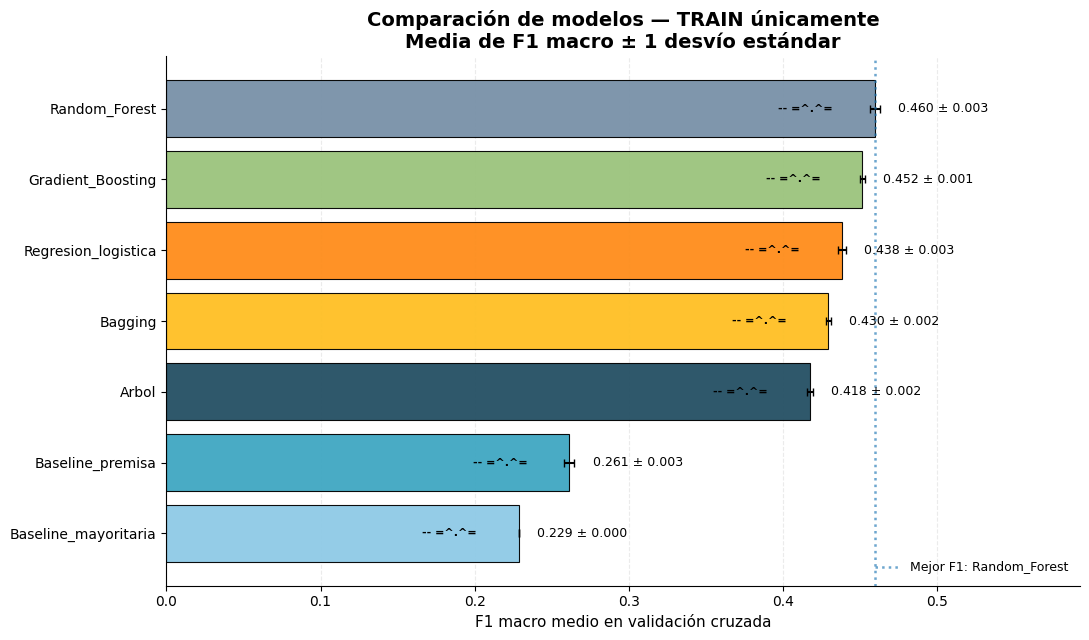

In [24]:
# ============================================================
# VISUALIZACIÓN DE LA COMPARACIÓN EN VALIDACIÓN CRUZADA
# ============================================================

import matplotlib.pyplot as plt

# Ordenar de menor a mayor F1 macro
plot_cv = tabla_cv.sort_values("F1_macro_CV")

fig, ax = plt.subplots(figsize=(11, 6.5))

# Paleta diferenciada para facilitar la lectura entre modelos.
colores = [
    "#8ecae6",
    "#3fa7c2",
    "#244f63",
    "#ffbf24",
    "#ff8c1a",
    "#9bc37c",
    "#7891a8",
]

# Barras
bars = ax.barh(
    plot_cv.index,
    plot_cv["F1_macro_CV"],
    xerr=plot_cv["F1_macro_std"],
    color=colores[:len(plot_cv)],
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    capsize=3,
)

# Título y ejes
ax.set_title(
    "Comparación de modelos — TRAIN únicamente\n"
    "Media de F1 macro ± 1 desvío estándar",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel(
    "F1 macro medio en validación cruzada",
    fontsize=11,
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25,
)

ax.set_axisbelow(True)

# Dejamos espacio a la derecha para valores
maximo = (
    plot_cv["F1_macro_CV"]
    + plot_cv["F1_macro_std"]
).max()

ax.set_xlim(
    0,
    min(1, maximo + 0.13),
)


# ------------------------------------------------------------
# Gatitos pequeños "corriendo" sobre cada barra
# ------------------------------------------------------------

for i, (valor, std) in enumerate(
    zip(
        plot_cv["F1_macro_CV"],
        plot_cv["F1_macro_std"],
    )
):
    # Rayitas de movimiento + gatito ASCII
    ax.text(
        valor - 0.045,
        i,
        "-- =^.^=",
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="black",
    )

    # Valor numérico
    ax.text(
        valor + std + 0.012,
        i,
        f"{valor:.3f} ± {std:.3f}",
        ha="left",
        va="center",
        fontsize=9,
    )


# ------------------------------------------------------------
# Línea de referencia del mejor F1
# ------------------------------------------------------------

# Referencia visual del mayor F1 macro medio.
mejor_modelo = (
    plot_cv["F1_macro_CV"]
    .idxmax()
)

mejor_valor = (
    plot_cv["F1_macro_CV"]
    .max()
)

ax.axvline(
    mejor_valor,
    linestyle=":",
    linewidth=1.8,
    alpha=0.65,
    label=f"Mejor F1: {mejor_modelo}",
)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9,
)

# Sacar bordes innecesarios
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

## 16.3 Experimento controlado: ¿qué hace `class_weight="balanced"`?

La primera ejecución del TP mostró un patrón que debe explicarse, no ocultarse:

- el modelo balanceado podía mejorar F1 macro y balanced accuracy;
- al mismo tiempo podía bajar accuracy, porque dejaba de favorecer a la clase mayoritaria.

Para comprobar si ese comportamiento se debe realmente al balanceo y no solo a una coincidencia, hacemos un experimento controlado con Gradient Boosting:

- misma arquitectura;
- mismo preprocesamiento;
- mismos folds;
- único cambio: `class_weight=None` vs. `class_weight="balanced"`.

### Qué esperamos observar

Si el balanceo funciona como se supone, puede ocurrir que:

- baje accuracy;
- suba F1 macro o balanced accuracy;
- se distribuya mejor el recall entre clases.

Este bloque no selecciona el modelo final. Es un experimento explicativo.

In [25]:
# ============================================================
# 16.3 CLASS WEIGHT: EXPERIMENTO CONTROLADO EN CV
# ============================================================

# Dos modelos idénticos salvo por class_weight permiten aislar
# el efecto del balanceo.
gb_sin_balance = pipeline_con(
    HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=150,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=0.1,
        class_weight=None,
        random_state=RANDOM_STATE,
    )
)

gb_balanceado = pipeline_con(
    HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=150,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=0.1,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )
)

# Resultados comparables para ambas configuraciones.
filas_balanceo_cv = []

# Misma validación cruzada para ambas variantes.
for nombre, estimador in {
    "GB_sin_balance": gb_sin_balance,
    "GB_balanceado": gb_balanceado,
}.items():

    salida = cross_validate(
        estimator=estimador,
        X=X_select,
        y=y_select,
        cv=CV,
        scoring={
            "f1_macro": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy",
            "recall_macro": "recall_macro",
        },
        n_jobs=1,
        return_train_score=False,
    )

    filas_balanceo_cv.append({
        "Modelo": nombre,
        "Accuracy_CV": salida["test_accuracy"].mean(),
        "Balanced_accuracy_CV": salida["test_balanced_accuracy"].mean(),
        "Recall_macro_CV": salida["test_recall_macro"].mean(),
        "F1_macro_CV": salida["test_f1_macro"].mean(),
    })

# Tabla resumen utilizada en la interpretación posterior.
tabla_balanceo_cv = (
    pd.DataFrame(
        filas_balanceo_cv
    )
    .set_index(
        "Modelo"
    )
)

display(
    tabla_balanceo_cv.round(4)
)

,Accuracy_CV,Balanced_accuracy_CV,Recall_macro_CV,F1_macro_CV
Modelo,,,,
GB_sin_balance,0.5379,0.3803,0.3803,0.3476
GB_balanceado,0.4575,0.5079,0.5079,0.4516


In [27]:
# ============================================================
# INTERPRETACIÓN DEL TRADE-OFF DE BALANCEO EN CV
# ============================================================

# Se recuperan ambas variantes para calcular diferencias directas.

sin_b = tabla_balanceo_cv.loc[
    "GB_sin_balance"
]
con_b = tabla_balanceo_cv.loc[
    "GB_balanceado"
]

# Deltas: configuración balanceada menos configuración sin balance.
delta_acc_balanceo_cv = (
    con_b["Accuracy_CV"]
    - sin_b["Accuracy_CV"]
)

delta_f1_balanceo_cv = (
    con_b["F1_macro_CV"]
    - sin_b["F1_macro_CV"]
)

delta_balacc_balanceo_cv = (
    con_b["Balanced_accuracy_CV"]
    - sin_b["Balanced_accuracy_CV"]
)

# Lectura automática a partir del signo de los cambios observados.
if (
    delta_acc_balanceo_cv < 0
    and delta_f1_balanceo_cv > 0
):
    lectura_balanceo_cv = (
        "El experimento confirma el trade-off esperado: al ponderar las "
        "clases de manera balanceada baja accuracy, pero mejora F1 macro. "
        "El modelo deja de optimizar principalmente la clase más frecuente "
        "y reparte mejor su capacidad predictiva entre las tres categorías."
    )
elif delta_acc_balanceo_cv < 0:
    lectura_balanceo_cv = (
        "El balanceo reduce accuracy, pero en esta ejecución no produce "
        "una mejora simultánea de F1 macro. Por lo tanto, no corresponde "
        "defender class_weight='balanced' solo por principio: debe juzgarse "
        "con las métricas obtenidas."
    )
else:
    lectura_balanceo_cv = (
        "En esta ejecución el balanceo no produjo la caída de accuracy "
        "observada en la versión anterior. El efecto de class_weight depende "
        "de la representación de features y del modelo, por eso se evalúa "
        "empíricamente."
    )

display(
    Markdown(
        f'''
### Interpretación del experimento de balanceo

- Δ accuracy (balanced − sin balance): **{delta_acc_balanceo_cv:+.4f}**
- Δ balanced accuracy: **{delta_balacc_balanceo_cv:+.4f}**
- Δ F1 macro: **{delta_f1_balanceo_cv:+.4f}**

{lectura_balanceo_cv}

La elección de F1 macro como métrica principal es deliberada: la pregunta de investigación busca distinguir las tres severidades con igual importancia conceptual. `Accuracy` se mantiene como métrica complementaria y cualquier deterioro se reporta explícitamente.
'''
    )
)


### Interpretación del experimento de balanceo

- Δ accuracy (balanced − sin balance): **-0.0804**
- Δ balanced accuracy: **+0.1276**
- Δ F1 macro: **+0.1040**

El experimento confirma el trade-off esperado: al ponderar las clases de manera balanceada baja accuracy, pero mejora F1 macro. El modelo deja de optimizar principalmente la clase más frecuente y reparte mejor su capacidad predictiva entre las tres categorías.

La elección de F1 macro como métrica principal es deliberada: la pregunta de investigación busca distinguir las tres severidades con igual importancia conceptual. `Accuracy` se mantiene como métrica complementaria y cualquier deterioro se reporta explícitamente.


# 17. Ajuste de hiperparámetros

No tuneamos un modelo elegido de antemano. Primero se identifica la mejor familia base y recién entonces se ajusta esa familia con `RandomizedSearchCV`.

Esto responde directamente al criterio de explicar cómo se llegó a la elección del algoritmo frente a otras alternativas.

In [28]:
# ============================================================
# IDENTIFICACIÓN DE LA MEJOR FAMILIA BASE
# ============================================================

# Los baselines se excluyen del ranking que decide qué familia se ajusta.

MODELOS_APRENDIDOS = [
    "Regresion_logistica",
    "Arbol",
    "Bagging",
    "Random_Forest",
    "Gradient_Boosting",
]

ranking_ml = (
    tabla_cv
    .loc[MODELOS_APRENDIDOS]
    .sort_values("F1_macro_CV", ascending=False)
)

# Familia con mayor F1 macro medio antes del tuning.
familia_ganadora_base = ranking_ml.index[0]

print(
    "Familia con mayor F1 macro antes del tuning:",
    familia_ganadora_base,
)

Familia con mayor F1 macro antes del tuning: Random_Forest


## 17.1 Espacio de hiperparámetros

El espacio depende de la familia que haya ganado. No tiene sentido ajustar los mismos parámetros para algoritmos conceptualmente distintos.

In [29]:
# ============================================================
# ESPACIO DE HIPERPARÁMETROS SEGÚN LA FAMILIA GANADORA
# ============================================================

# Se clona el pipeline para no modificar la configuración base.

estimador_tuning = clone(modelos[familia_ganadora_base])

# Cada familia recibe un espacio de búsqueda propio.
if familia_ganadora_base == "Regresion_logistica":
    param_dist = {
        "model__C": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 10.0],
        "model__class_weight": [None, "balanced"],
    }

elif familia_ganadora_base == "Arbol":
    param_dist = {
        "model__max_depth": [6, 10, 14, 18, 24, None],
        "model__min_samples_split": [2, 10, 30, 60],
        "model__min_samples_leaf": [2, 10, 30, 60],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"],
    }

elif familia_ganadora_base == "Bagging":
    param_dist = {
        "model__n_estimators": [100, 150, 250, 350],
        "model__max_samples": [0.6, 0.8, 1.0],
        "model__max_features": [0.7, 1.0],
        "model__estimator__max_depth": [10, 20, None],
        "model__estimator__min_samples_leaf": [1, 2, 5],
    }

elif familia_ganadora_base == "Random_Forest":
    param_dist = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [12, 20, 30, None],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5, 1.0],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
    }

elif familia_ganadora_base == "Gradient_Boosting":
    param_dist = {
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_iter": [100, 150, 250],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 40, 80],
        "model__l2_regularization": [0.0, 0.1, 1.0],
        "model__class_weight": [None, "balanced"],
    }

else:
    raise ValueError("Familia sin espacio de tuning.")

In [30]:
# ============================================================
# BÚSQUEDA ALEATORIA ACOTADA DE HIPERPARÁMETROS
# ============================================================

import time


# ------------------------------------------------------------
# Presupuesto computacional
# ------------------------------------------------------------

# Presupuesto reducido para que la notebook sea ejecutable en Colab.
N_ITER_TUNING = 4
N_TUNING = 25_000


# ------------------------------------------------------------
# Espacio de búsqueda acotado
# ------------------------------------------------------------

# Si ganó Random Forest se restringe el espacio a configuraciones
# razonables en costo computacional.
if familia_ganadora_base == "Random_Forest":

    param_dist = {
        "model__n_estimators": [
            80,
            120,
            160,
        ],
        "model__max_depth": [
            12,
            18,
            None,
        ],
        "model__min_samples_leaf": [
            2,
            5,
        ],
        "model__max_features": [
            "sqrt",
            0.5,
        ],
        "model__class_weight": [
            "balanced_subsample",
        ],
    }


# ------------------------------------------------------------
# Muestra estratificada SOLO para el tuning
# ------------------------------------------------------------

# Muestra estratificada utilizada exclusivamente durante la búsqueda.
if len(X_select) > N_TUNING:

    X_tune, _, y_tune, _ = train_test_split(
        X_select,
        y_select,
        train_size=N_TUNING,
        stratify=y_select,
        random_state=RANDOM_STATE,
    )

else:

    X_tune = X_select.copy()
    y_tune = y_select.copy()


# ------------------------------------------------------------
# Información de ejecución
# ------------------------------------------------------------

print("Inicio del ajuste de hiperparámetros")
print(f"Familia seleccionada: {familia_ganadora_base}")
print(f"Observaciones utilizadas para tuning: {len(X_tune):,}")
print(f"Candidatos aleatorios: {N_ITER_TUNING}")
print(f"Folds: {CV.get_n_splits()}")
print(
    f"Total de fits de búsqueda: "
    f"{N_ITER_TUNING * CV.get_n_splits()}"
)
print("-" * 60)


# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

# RandomizedSearchCV conserva la lógica de tuning con un presupuesto acotado.
busqueda = RandomizedSearchCV(
    estimator=estimador_tuning,
    param_distributions=param_dist,
    n_iter=N_ITER_TUNING,
    scoring="f1_macro",
    cv=CV,
    n_jobs=1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=False,
    verbose=2,
)


inicio_tuning = time.perf_counter()

# Ejecución de la búsqueda sobre la muestra de tuning.
busqueda.fit(
    X_tune,
    y_tune,
)

fin_tuning = time.perf_counter()

tiempo_tuning = (
    fin_tuning - inicio_tuning
)


# ------------------------------------------------------------
# Nombre del modelo ajustado
# ------------------------------------------------------------

nombre_ajustado = (
    f"{familia_ganadora_base}_ajustado"
)


# ------------------------------------------------------------
# Resultados de la búsqueda
# ------------------------------------------------------------

print()
print("=" * 60)
print("BÚSQUEDA COMPLETADA")
print("=" * 60)

print(
    f"Tiempo de búsqueda: "
    f"{tiempo_tuning / 60:.2f} min"
)

print("\nMejores hiperparámetros:")

for parametro, valor in busqueda.best_params_.items():
    print(
        f" - {parametro}: {valor}"
    )

print(
    f"\nMejor F1 macro durante la búsqueda: "
    f"{busqueda.best_score_:.4f}"
)


# ------------------------------------------------------------
# Validación del mejor modelo sobre el conjunto completo
# de selección
# ------------------------------------------------------------

print()
print(
    "Validando la configuración elegida "
    "sobre las 50.000 observaciones de selección..."
)

resultado_tuned = cross_validate(
    estimator=busqueda.best_estimator_,
    X=X_select,
    y=y_select,
    cv=CV,
    scoring={
        "f1_macro": "f1_macro",
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
    },
    n_jobs=1,
    return_train_score=False,
)


f1_tuned_cv = (
    resultado_tuned[
        "test_f1_macro"
    ].mean()
)

f1_tuned_std = (
    resultado_tuned[
        "test_f1_macro"
    ].std()
)

f1_base_familia = (
    ranking_ml.loc[
        familia_ganadora_base,
        "F1_macro_CV",
    ]
)

mejora_tuning = (
    f1_tuned_cv
    - f1_base_familia
)


# ------------------------------------------------------------
# Resultado final
# ------------------------------------------------------------

print()
print("=" * 60)
print("RESULTADO FINAL DEL TUNING")
print("=" * 60)

print(
    f"F1 macro CV base: "
    f"{f1_base_familia:.4f}"
)

print(
    f"F1 macro CV ajustado: "
    f"{f1_tuned_cv:.4f} "
    f"± {f1_tuned_std:.4f}"
)

print(
    f"Mejora absoluta: "
    f"{mejora_tuning:+.4f}"
)

Inicio del ajuste de hiperparámetros
Familia seleccionada: Random_Forest
Observaciones utilizadas para tuning: 25,000
Candidatos aleatorios: 4
Folds: 3
Total de fits de búsqueda: 12
------------------------------------------------------------
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END model__class_weight=balanced_subsample, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__n_estimators=160; total time=  10.1s
[CV] END model__class_weight=balanced_subsample, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__n_estimators=160; total time=   8.6s
[CV] END model__class_weight=balanced_subsample, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__n_estimators=160; total time=  10.4s
[CV] END model__class_weight=balanced_subsample, model__max_depth=18, model__max_features=sqrt, model__min_samples_leaf=2, model__n_estimators=120; total time=   3.1s
[CV] END model__class_weig

In [31]:
# ============================================================
# 17.2 ¿CUÁNTO APORTÓ REALMENTE EL TUNING?
# ============================================================

# Referencia de la familia base antes del ajuste.
f1_base_familia = ranking_ml.loc[
    familia_ganadora_base,
    "F1_macro_CV",
]

# Diferencia absoluta atribuible al ajuste.
mejora_tuning = (
    busqueda.best_score_
    - f1_base_familia
)

# La interpretación depende de la magnitud de la mejora, no solo de su signo.
if abs(mejora_tuning) < 0.001:
    lectura_tuning = (
        "La mejora es del orden de una diezmilésima/milésima y resulta "
        "prácticamente despreciable frente a la variabilidad natural de CV. "
        "Esto respalda la hipótesis H3: mayor búsqueda de hiperparámetros no "
        "implica una mejora sustantiva."
    )
elif abs(mejora_tuning) < 0.005:
    lectura_tuning = (
        "La mejora existe, pero es pequeña. Debe compararse con el desvío "
        "entre folds antes de justificar una configuración más compleja."
    )
else:
    lectura_tuning = (
        "El tuning produce una mejora suficientemente visible como para "
        "ser considerada en la selección, aunque la decisión final seguirá "
        "aplicando la regla de parsimonia."
    )

display(
    Markdown(
        f'''
## 17.2 Interpretación del tuning

- Familia base: **{familia_ganadora_base}**
- F1 macro CV base: **{f1_base_familia:.4f}**
- Mejor F1 macro CV tras tuning: **{busqueda.best_score_:.4f}**
- Mejora absoluta: **{mejora_tuning:+.4f}**

{lectura_tuning}

Este resultado se reporta aunque la mejora sea mínima. No se presenta el tuning como un éxito por el solo hecho de haber ejecutado una búsqueda.
'''
    )
)


## 17.2 Interpretación del tuning

- Familia base: **Random_Forest**
- F1 macro CV base: **0.4599**
- Mejor F1 macro CV tras tuning: **0.4621**
- Mejora absoluta: **+0.0022**

La mejora existe, pero es pequeña. Debe compararse con el desvío entre folds antes de justificar una configuración más compleja.

Este resultado se reporta aunque la mejora sea mínima. No se presenta el tuning como un éxito por el solo hecho de haber ejecutado una búsqueda.


# 18. Elección final antes de test: desempeño + parsimonia

Aplicamos una regla de un error estándar: entre los modelos cuyo F1 macro medio queda dentro de un error estándar del mejor, elegimos el de menor complejidad conceptual.

Así evitamos defender un ensamble pesado por una mejora que no se distingue de la variabilidad de CV.

In [32]:
# ============================================================
# SELECCIÓN FINAL ANTES DE OBSERVAR TEST
# ============================================================

# Se combinan modelos base y versión ajustada para aplicar
# una regla de parsimonia basada en un error estándar (1-SE).

tabla_seleccion = (
    tabla_cv
    .loc[
        MODELOS_APRENDIDOS,
        ["F1_macro_CV", "F1_macro_std"],
    ]
    .copy()
)

# Incorporación de la mejor configuración ajustada al ranking.
idx_best = busqueda.best_index_

tabla_seleccion.loc[
    nombre_ajustado,
    "F1_macro_CV",
] = busqueda.best_score_

tabla_seleccion.loc[
    nombre_ajustado,
    "F1_macro_std",
] = busqueda.cv_results_["std_test_score"][idx_best]

tabla_seleccion = tabla_seleccion.sort_values(
    "F1_macro_CV",
    ascending=False,
)

display(tabla_seleccion.round(4))

# Umbral 1-SE respecto del mejor F1 macro medio.
mejor_media = tabla_seleccion["F1_macro_CV"].max()
mejor_nombre_media = tabla_seleccion["F1_macro_CV"].idxmax()
mejor_std = tabla_seleccion.loc[mejor_nombre_media, "F1_macro_std"]

error_estandar_mejor = mejor_std / np.sqrt(N_SPLITS_CV)
umbral_1se = mejor_media - error_estandar_mejor

candidatos_1se = tabla_seleccion[
    tabla_seleccion["F1_macro_CV"] >= umbral_1se
].copy()

# Escala ordinal de complejidad usada para resolver candidatos cercanos.
complejidad_base = {
    "Regresion_logistica": 1.0,
    "Arbol": 2.0,
    "Bagging": 3.0,
    "Random_Forest": 4.0,
    "Gradient_Boosting": 4.0,
}

complejidad = dict(complejidad_base)
complejidad[nombre_ajustado] = complejidad_base[familia_ganadora_base] + 0.1

candidatos_1se["Complejidad"] = [
    complejidad[nombre]
    for nombre in candidatos_1se.index
]

# Entre los candidatos dentro de 1-SE se prioriza el más simple.
modelo_elegido_nombre = (
    candidatos_1se
    .sort_values(
        ["Complejidad", "F1_macro_CV"],
        ascending=[True, False],
    )
    .index[0]
)

print(f"Mejor media CV: {mejor_nombre_media} ({mejor_media:.4f})")
print(f"Error estándar del mejor: {error_estandar_mejor:.4f}")
print(f"Umbral 1-SE: {umbral_1se:.4f}")

print("\nModelos dentro de 1-SE:")
display(candidatos_1se.round(4))

print("\nModelo elegido por regla 1-SE:", modelo_elegido_nombre)

,F1_macro_CV,F1_macro_std
Modelo,,
Random_Forest_ajustado,0.4621,0.0024
Random_Forest,0.4599,0.0030
Gradient_Boosting,0.4516,0.0014
Regresion_logistica,0.4383,0.0027
Bagging,0.4295,0.0016
Arbol,0.4178,0.0017


Mejor media CV: Random_Forest_ajustado (0.4621)
Error estándar del mejor: 0.0014
Umbral 1-SE: 0.4607

Modelos dentro de 1-SE:


,F1_macro_CV,F1_macro_std,Complejidad
Modelo,,,
Random_Forest_ajustado,0.4621,0.0024,4.1



Modelo elegido por regla 1-SE: Random_Forest_ajustado


# 19. Evaluación final sobre test

Recién ahora se utiliza test.

## Protocolo

- Si gana la versión ajustada, se clona `best_estimator_`.
- Si gana una versión base, se clona el pipeline correspondiente.
- Se reentrena con todo train.
- Se evalúa test una sola vez.

También se calculan los dos baselines sobre el mismo test.

In [33]:
# ============================================================
# 19. EVALUACIÓN FINAL SOBRE TEST
# Preparación del modelo y función de evaluación
# ============================================================

import time
import numpy as np

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    log_loss,
)


# ------------------------------------------------------------
# 1. Recuperar el modelo seleccionado
# ------------------------------------------------------------

# Si el modelo elegido corresponde a la versión ajustada,
# se utiliza el mejor estimador obtenido durante el tuning.
if (
    "nombre_ajustado" in globals()
    and modelo_elegido_nombre == nombre_ajustado
):

    if "busqueda" not in globals():
        raise RuntimeError(
            "El modelo seleccionado es el ajustado, "
            "pero no existe el objeto 'busqueda'. "
            "Ejecutar primero la sección de tuning."
        )

    modelo_final = clone(
        busqueda.best_estimator_
    )

# Si ganó uno de los modelos base, se recupera
# directamente desde el diccionario de modelos.
else:

    if modelo_elegido_nombre not in modelos:
        raise ValueError(
            f"El modelo '{modelo_elegido_nombre}' "
            "no se encuentra en el diccionario 'modelos'."
        )

    modelo_final = clone(
        modelos[modelo_elegido_nombre]
    )


# ------------------------------------------------------------
# 2. Función de evaluación final
# ------------------------------------------------------------

def evaluar_final(
    nombre,
    estimador,
    Xtr,
    ytr,
    Xte,
    yte,
):
    """
    Entrena un estimador con el conjunto de entrenamiento
    completo y calcula sus métricas sobre el conjunto de test.

    El conjunto de test se utiliza únicamente en esta etapa final.
    """

    # --------------------------------------------------------
    # Entrenamiento
    # --------------------------------------------------------

    inicio = time.perf_counter()

    estimador.fit(
        Xtr,
        ytr,
    )

    tiempo_fit = (
        time.perf_counter()
        - inicio
    )


    # --------------------------------------------------------
    # Predicción
    # --------------------------------------------------------

    pred = estimador.predict(
        Xte
    )


    # --------------------------------------------------------
    # Métricas macro
    # --------------------------------------------------------

    (
        precision_macro,
        recall_macro,
        f1_macro,
        _,
    ) = precision_recall_fscore_support(
        yte,
        pred,
        average="macro",
        zero_division=0,
    )


    # --------------------------------------------------------
    # F1 ponderado
    # --------------------------------------------------------

    (
        _,
        _,
        f1_weighted,
        _,
    ) = precision_recall_fscore_support(
        yte,
        pred,
        average="weighted",
        zero_division=0,
    )


    # --------------------------------------------------------
    # Resultados básicos
    # --------------------------------------------------------

    fila = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(
            yte,
            pred,
        ),
        "Balanced_accuracy": balanced_accuracy_score(
            yte,
            pred,
        ),
        "Precision_macro": precision_macro,
        "Recall_macro": recall_macro,
        "F1_macro": f1_macro,
        "F1_weighted": f1_weighted,
        "Fit_time_s": tiempo_fit,
    }


    # --------------------------------------------------------
    # Métricas basadas en probabilidades
    # --------------------------------------------------------

    proba = None

    if hasattr(
        estimador,
        "predict_proba",
    ):

        try:

            proba = estimador.predict_proba(
                Xte
            )

            clases_estimador = list(
                estimador.classes_
            )

            fila[
                "ROC_AUC_macro_OvR"
            ] = roc_auc_score(
                yte,
                proba,
                labels=clases_estimador,
                multi_class="ovr",
                average="macro",
            )

            fila[
                "Log_loss"
            ] = log_loss(
                yte,
                proba,
                labels=clases_estimador,
            )

        except Exception as exc:

            fila[
                "ROC_AUC_macro_OvR"
            ] = np.nan

            fila[
                "Log_loss"
            ] = np.nan

            print(
                "Advertencia: no se pudieron calcular "
                "ROC-AUC / Log-loss:"
            )

            print(
                type(exc).__name__,
                "-",
                exc,
            )


    return (
        fila,
        estimador,
        pred,
        proba,
    )


# ------------------------------------------------------------
# 3. Verificación de la celda
# ------------------------------------------------------------

print("=" * 60)
print("MODELO FINAL PREPARADO")
print("=" * 60)

print(
    f"Modelo seleccionado: "
    f"{modelo_elegido_nombre}"
)

print(
    f"Estimador preparado: "
    f"{modelo_final.__class__.__name__}"
)

print(
    "Función evaluar_final() definida correctamente."
)

print()
print(
    "Todavía NO se utilizó el conjunto de test. "
    "La evaluación se ejecuta en la siguiente celda."
)

MODELO FINAL PREPARADO
Modelo seleccionado: Random_Forest_ajustado
Estimador preparado: Pipeline
Función evaluar_final() definida correctamente.

Todavía NO se utilizó el conjunto de test. La evaluación se ejecuta en la siguiente celda.


In [34]:
# ============================================================
# 19.1 EVALUACIÓN FINAL SOBRE TEST
# ============================================================

import time


# ------------------------------------------------------------
# Función liviana para los baselines
# ------------------------------------------------------------

def evaluar_baseline_rapido(
    nombre,
    estimador,
    Xtr,
    ytr,
    Xte,
    yte,
):
    """
    Evalúa un baseline con las métricas necesarias para la
    comparación principal, evitando cálculos adicionales
    que no son relevantes para estos modelos de referencia.
    """

    inicio = time.perf_counter()

    estimador.fit(
        Xtr,
        ytr,
    )

    pred = estimador.predict(
        Xte
    )

    tiempo = (
        time.perf_counter()
        - inicio
    )

    (
        precision_macro,
        recall_macro,
        f1_macro,
        _,
    ) = precision_recall_fscore_support(
        yte,
        pred,
        average="macro",
        zero_division=0,
    )

    (
        _,
        _,
        f1_weighted,
        _,
    ) = precision_recall_fscore_support(
        yte,
        pred,
        average="weighted",
        zero_division=0,
    )

    resultado = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(
            yte,
            pred,
        ),
        "Balanced_accuracy": balanced_accuracy_score(
            yte,
            pred,
        ),
        "Precision_macro": precision_macro,
        "Recall_macro": recall_macro,
        "F1_macro": f1_macro,
        "F1_weighted": f1_weighted,
        "Fit_time_s": tiempo,
        "ROC_AUC_macro_OvR": np.nan,
        "Log_loss": np.nan,
    }

    return (
        resultado,
        estimador,
        pred,
    )


# ============================================================
# 1. BASELINE DE CLASE MAYORITARIA
# ============================================================

print("[1/3] Evaluando baseline de clase mayoritaria...")

inicio = time.perf_counter()

(
    resultado_dummy,
    dummy_fit,
    pred_dummy,
) = evaluar_baseline_rapido(
    "Baseline_mayoritaria",
    clone(
        modelos[
            "Baseline_mayoritaria"
        ]
    ),
    X_train,
    y_train,
    X_test,
    y_test,
)

print(
    f"      terminado en "
    f"{time.perf_counter() - inicio:.2f} s"
)


# ============================================================
# 2. BASELINE POR TIPO DE PREMISA
# ============================================================

print(
    "[2/3] Evaluando baseline contextual por premisa..."
)

inicio = time.perf_counter()

(
    resultado_contexto,
    contexto_fit,
    pred_contexto,
) = evaluar_baseline_rapido(
    "Baseline_premisa",
    clone(
        modelos[
            "Baseline_premisa"
        ]
    ),
    X_train,
    y_train,
    X_test,
    y_test,
)

print(
    f"      terminado en "
    f"{time.perf_counter() - inicio:.2f} s"
)


# ============================================================
# 3. MODELO FINAL
# ============================================================

print()
print(
    f"[3/3] Entrenando y evaluando modelo final: "
    f"{modelo_elegido_nombre}"
)

print(
    f"      Train: {len(X_train):,} observaciones"
)

print(
    f"      Test:  {len(X_test):,} observaciones"
)

inicio = time.perf_counter()

(
    resultado_modelo,
    modelo_final,
    pred_final,
    proba_final,
) = evaluar_final(
    modelo_elegido_nombre,
    modelo_final,
    X_train,
    y_train,
    X_test,
    y_test,
)

tiempo_modelo_final = (
    time.perf_counter()
    - inicio
)

print(
    f"      terminado en "
    f"{tiempo_modelo_final / 60:.2f} min"
)


# ============================================================
# TABLA FINAL
# ============================================================

tabla_test = (
    pd.DataFrame(
        [
            resultado_dummy,
            resultado_contexto,
            resultado_modelo,
        ]
    )
    .set_index(
        "Modelo"
    )
)


print()
print("=" * 70)
print("EVALUACIÓN FINAL SOBRE TEST COMPLETADA")
print("=" * 70)

display(
    tabla_test.round(4)
)

[1/3] Evaluando baseline de clase mayoritaria...
      terminado en 5.16 s
[2/3] Evaluando baseline contextual por premisa...
      terminado en 2.30 s

[3/3] Entrenando y evaluando modelo final: Random_Forest_ajustado
      Train: 223,596 observaciones
      Test:  55,899 observaciones
      terminado en 0.94 min

EVALUACIÓN FINAL SOBRE TEST COMPLETADA


,Accuracy,Balanced_accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,Fit_time_s,ROC_AUC_macro_OvR,Log_loss
Modelo,,,,,,,,,
Baseline_mayoritaria,0.5215,0.3333,0.1738,0.3333,0.2285,0.3575,2.2004,NaN,NaN
Baseline_premisa,0.5264,0.3436,0.3474,0.3436,0.2608,0.3878,0.6912,NaN,NaN
Random_Forest_ajustado,0.4679,0.5136,0.4832,0.5136,0.4603,0.4796,51.6878,0.6822,0.9815


In [35]:
# ============================================================
# 19.2 INTERPRETACIÓN EXPLÍCITA: ACCURACY VS. F1 MACRO
# ============================================================

# Métricas del modelo final y de los dos baselines.
acc_modelo = resultado_modelo["Accuracy"]
acc_dummy = resultado_dummy["Accuracy"]
acc_contexto = resultado_contexto["Accuracy"]

f1_modelo = resultado_modelo["F1_macro"]
f1_dummy = resultado_dummy["F1_macro"]
f1_contexto = resultado_contexto["F1_macro"]

# Diferencias respecto de cada referencia.
delta_acc_dummy = acc_modelo - acc_dummy
delta_acc_contexto = acc_modelo - acc_contexto

delta_f1_dummy = f1_modelo - f1_dummy
delta_f1_contexto = f1_modelo - f1_contexto

# La lectura reconoce cualquier costo de accuracy frente a los baselines.
if (
    acc_modelo < acc_dummy
    or acc_modelo < acc_contexto
):
    lectura_accuracy = (
        "El modelo final NO domina a los baselines en todas las métricas. "
        "Su accuracy es inferior al menos a uno de ellos. Esto debe leerse "
        "junto con F1 macro y balanced accuracy: optimizar el equilibrio entre "
        "clases puede sacrificar porcentaje global de aciertos, especialmente "
        "cuando MISDEMEANOR es la clase más frecuente."
    )
else:
    lectura_accuracy = (
        "En esta ejecución el modelo final también iguala o supera a los "
        "baselines en accuracy. Aun así, F1 macro continúa siendo la métrica "
        "principal porque evita que la clase mayoritaria domine la evaluación."
    )

display(
    Markdown(
        f'''
## 19.2 Interpretación de los resultados globales

El modelo final obtuvo:

- **Accuracy:** {acc_modelo:.4f}
- **F1 macro:** {f1_modelo:.4f}
- **Balanced accuracy:** {resultado_modelo["Balanced_accuracy"]:.4f}

Comparación con los baselines:

| Comparación | Δ Accuracy | Δ F1 macro |
|---|---:|---:|
| vs. clase mayoritaria | {delta_acc_dummy:+.4f} | {delta_f1_dummy:+.4f} |
| vs. baseline por premisa | {delta_acc_contexto:+.4f} | {delta_f1_contexto:+.4f} |

{lectura_accuracy}

Por eso **no se oculta una eventual caída de accuracy**. La decisión metodológica es priorizar F1 macro porque las tres clases son relevantes para la pregunta de investigación; accuracy queda reportada como contrapeso para mostrar el costo de esa elección.
'''
    )
)


## 19.2 Interpretación de los resultados globales

El modelo final obtuvo:

- **Accuracy:** 0.4679
- **F1 macro:** 0.4603
- **Balanced accuracy:** 0.5136

Comparación con los baselines:

| Comparación | Δ Accuracy | Δ F1 macro |
|---|---:|---:|
| vs. clase mayoritaria | -0.0536 | +0.2318 |
| vs. baseline por premisa | -0.0584 | +0.1995 |

El modelo final NO domina a los baselines en todas las métricas. Su accuracy es inferior al menos a uno de ellos. Esto debe leerse junto con F1 macro y balanced accuracy: optimizar el equilibrio entre clases puede sacrificar porcentaje global de aciertos, especialmente cuando MISDEMEANOR es la clase más frecuente.

Por eso **no se oculta una eventual caída de accuracy**. La decisión metodológica es priorizar F1 macro porque las tres clases son relevantes para la pregunta de investigación; accuracy queda reportada como contrapeso para mostrar el costo de esa elección.


# 20. Resultados por clase

Se informa precision, recall, F1 y support de cada clase para detectar si el modelo sacrifica una categoría minoritaria aunque la métrica global parezca buena.

In [36]:
# ============================================================
# MÉTRICAS DETALLADAS POR CLASE
# ============================================================

# Permiten detectar si las métricas globales ocultan diferencias
# entre VIOLATION, MISDEMEANOR y FELONY.

reporte_dict = classification_report(
    y_test,
    pred_final,
    labels=CLASES,
    output_dict=True,
    zero_division=0,
)

# Se conserva el bloque de las tres clases objetivo.
reporte_clases = pd.DataFrame({
    clase: reporte_dict[clase]
    for clase in CLASES
}).T

display(
    reporte_clases[
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
VIOLATION,0.2910,0.6642,0.4047,9144.0
MISDEMEANOR,0.7047,0.4031,0.5128,29154.0
FELONY,0.4540,0.4734,0.4635,17601.0


## 20.1 Diagnóstico post-hoc del efecto de `class_weight`

La versión anterior mostraba una caída importante de accuracy junto con una mejora de F1 macro. Para no atribuir ese comportamiento al balanceo sin comprobarlo, repetimos un experimento controlado sobre el mismo test:

- Gradient Boosting sin ponderación;
- Gradient Boosting con `class_weight="balanced"`.

Este análisis ocurre después de haber seleccionado el modelo final. No se usa para cambiar el ganador. Su función es explicar el trade-off entre métricas y verificar el mecanismo observado.

In [37]:
# ============================================================
# 20.1 DIAGNÓSTICO POST-HOC DE CLASS_WEIGHT EN TEST
# ============================================================

# Se guardan modelos, predicciones y reportes para inspección posterior.
diagnosticos_balanceo = {}
filas_balanceo_test = []

# Ambas variantes se entrenan sobre train y se evalúan sobre el mismo test.
for nombre, estimador in {
    "GB_sin_balance": clone(
        gb_sin_balance
    ),
    "GB_balanceado": clone(
        gb_balanceado
    ),
}.items():

    fila, estimador_fit, pred, _ = evaluar_final(
        nombre,
        estimador,
        X_train,
        y_train,
        X_test,
        y_test,
    )

    # Métricas por clase para identificar qué categorías ganan o pierden.
    reporte = classification_report(
        y_test,
        pred,
        labels=CLASES,
        output_dict=True,
        zero_division=0,
    )

    fila.update({
        "Recall_VIOLATION": reporte["VIOLATION"]["recall"],
        "Precision_VIOLATION": reporte["VIOLATION"]["precision"],
        "Recall_MISDEMEANOR": reporte["MISDEMEANOR"]["recall"],
        "Precision_MISDEMEANOR": reporte["MISDEMEANOR"]["precision"],
        "Recall_FELONY": reporte["FELONY"]["recall"],
        "Precision_FELONY": reporte["FELONY"]["precision"],
    })

    filas_balanceo_test.append(
        fila
    )

    diagnosticos_balanceo[nombre] = {
        "modelo": estimador_fit,
        "pred": pred,
        "reporte": reporte,
    }

# Tabla compacta de métricas globales y por clase.
tabla_balanceo_test = (
    pd.DataFrame(
        filas_balanceo_test
    )
    .set_index(
        "Modelo"
    )
)

columnas_mostrar = [
    "Accuracy",
    "Balanced_accuracy",
    "F1_macro",
    "Recall_VIOLATION",
    "Recall_MISDEMEANOR",
    "Recall_FELONY",
    "Precision_VIOLATION",
    "Precision_MISDEMEANOR",
    "Precision_FELONY",
]

display(
    tabla_balanceo_test[
        columnas_mostrar
    ].round(4)
)

,Accuracy,Balanced_accuracy,F1_macro,Recall_VIOLATION,Recall_MISDEMEANOR,Recall_FELONY,Precision_VIOLATION,Precision_MISDEMEANOR,Precision_FELONY
Modelo,,,,,,,,,
GB_sin_balance,0.5462,0.3893,0.3606,0.0441,0.8959,0.2279,0.4659,0.5484,0.5416
GB_balanceado,0.4641,0.5153,0.4579,0.6834,0.3907,0.4719,0.2885,0.7121,0.4552


In [38]:
# ============================================================
# INTERPRETACIÓN DEL BALANCEO SOBRE TEST
# ============================================================

# Se calculan diferencias directas entre la versión balanceada
# y la no balanceada del mismo modelo.

sin_b_test = tabla_balanceo_test.loc[
    "GB_sin_balance"
]
con_b_test = tabla_balanceo_test.loc[
    "GB_balanceado"
]

delta_acc_test = (
    con_b_test["Accuracy"]
    - sin_b_test["Accuracy"]
)

delta_f1_test_balanceo = (
    con_b_test["F1_macro"]
    - sin_b_test["F1_macro"]
)

delta_rec_violation = (
    con_b_test["Recall_VIOLATION"]
    - sin_b_test["Recall_VIOLATION"]
)

delta_rec_felony = (
    con_b_test["Recall_FELONY"]
    - sin_b_test["Recall_FELONY"]
)

# Interpretación del trade-off observado.
if (
    delta_acc_test < 0
    and delta_f1_test_balanceo > 0
):
    texto_tradeoff = (
        "El balanceo intercambia parte de la accuracy global por una mejora "
        "del desempeño macro. Esto es consistente con el objetivo de no dejar "
        "que la clase mayoritaria determine por sí sola la evaluación."
    )
elif delta_acc_test < 0:
    texto_tradeoff = (
        "El balanceo reduce accuracy sin una mejora simultánea de F1 macro. "
        "En ese caso, el uso de pesos balanceados no queda justificado solo "
        "por la intención de tratar las clases por igual."
    )
else:
    texto_tradeoff = (
        "En la nueva representación de features el balanceo no genera el mismo "
        "patrón de caída de accuracy observado anteriormente. Esto confirma que "
        "el efecto depende tanto de los pesos como de la representación."
    )

display(
    Markdown(
        f'''
### Interpretación del balanceo sobre test

- Δ accuracy: **{delta_acc_test:+.4f}**
- Δ F1 macro: **{delta_f1_test_balanceo:+.4f}**
- Δ recall `VIOLATION`: **{delta_rec_violation:+.4f}**
- Δ recall `FELONY`: **{delta_rec_felony:+.4f}**

{texto_tradeoff}

Este análisis permite cuantificar el efecto del balanceo de clases. Una configuración balanceada puede reducir la accuracy global y, al mismo tiempo, mejorar el desempeño promedio entre clases. En este trabajo, ese intercambio se evalúa principalmente mediante F1 macro, ya que se busca otorgar igual importancia a las tres categorías de severidad.
'''
    )
)


### Interpretación del balanceo sobre test

- Δ accuracy: **-0.0821**
- Δ F1 macro: **+0.0974**
- Δ recall `VIOLATION`: **+0.6393**
- Δ recall `FELONY`: **+0.2440**

El balanceo intercambia parte de la accuracy global por una mejora del desempeño macro. Esto es consistente con el objetivo de no dejar que la clase mayoritaria determine por sí sola la evaluación.

Este análisis permite cuantificar el efecto del balanceo de clases. Una configuración balanceada puede reducir la accuracy global y, al mismo tiempo, mejorar el desempeño promedio entre clases. En este trabajo, ese intercambio se evalúa principalmente mediante F1 macro, ya que se busca otorgar igual importancia a las tres categorías de severidad.


# 21. Matriz de confusión

La versión normalizada permite leer la proporción de cada clase real que termina en cada predicción. También se conserva la matriz absoluta para cuantificar errores.

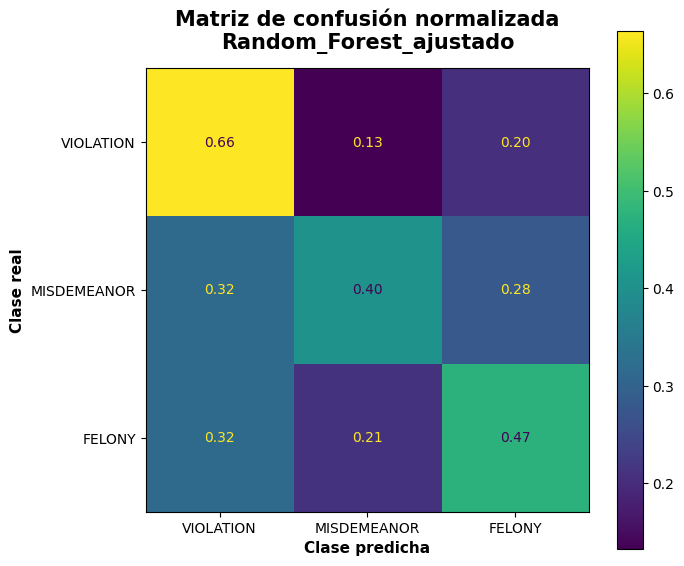

,pred_VIOLATION,pred_MISDEMEANOR,pred_FELONY
real_VIOLATION,6073,1210,1861
real_MISDEMEANOR,9243,11751,8160
real_FELONY,5555,3713,8333


In [39]:
# La matriz normalizada facilita comparar recalls entre clases
# aun cuando tengan frecuencias diferentes.
fig, ax = plt.subplots(figsize=(7.2, 6.2))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_final,
    labels=CLASES,
    normalize="true",
    values_format=".2f",
    cmap="viridis",
    ax=ax,
    colorbar=True,
)

ax.set_title(
    "Matriz de confusión normalizada\n"
    f"{modelo_elegido_nombre}",
    fontsize=15,
    fontweight="bold",
    pad=14,
)

ax.set_xlabel(
    "Clase predicha",
    fontsize=11,
    fontweight="bold",
)

ax.set_ylabel(
    "Clase real",
    fontsize=11,
    fontweight="bold",
)

ax.tick_params(
    axis="both",
    labelsize=10,
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Matriz de confusión absoluta
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    pred_final,
    labels=CLASES,
)

# La matriz absoluta conserva los conteos reales para análisis de errores.
cm_abs = pd.DataFrame(
    cm,
    index=[
        f"real_{c}"
        for c in CLASES
    ],
    columns=[
        f"pred_{c}"
        for c in CLASES
    ],
)

display(cm_abs)

## 21.1 Errores dominantes

Ordenamos las confusiones fuera de la diagonal para identificar cuáles pares de clases concentran más errores.

In [40]:
# ============================================================
# IDENTIFICACIÓN DE CONFUSIONES DOMINANTES
# ============================================================

# Se recorren solo las celdas fuera de la diagonal de la matriz.

errores = []

for i, real in enumerate(CLASES):
    for j, predicha in enumerate(CLASES):
        if i == j:
            continue

        errores.append({
            "Clase_real": real,
            "Clase_predicha": predicha,
            "Cantidad": int(cm[i, j]),
        })

# Ordenamiento de mayor a menor cantidad de errores.
errores_df = (
    pd.DataFrame(errores)
    .sort_values("Cantidad", ascending=False)
)

display(errores_df)

,Clase_real,Clase_predicha,Cantidad
2,MISDEMEANOR,VIOLATION,9243
3,MISDEMEANOR,FELONY,8160
4,FELONY,VIOLATION,5555
5,FELONY,MISDEMEANOR,3713
1,VIOLATION,FELONY,1861
0,VIOLATION,MISDEMEANOR,1210


# 22. Discriminación probabilística: ROC-AUC multiclase

Si el modelo final entrega probabilidades, se grafican curvas ROC One-vs-Rest.

AUC mide capacidad de ranking; no implica que las probabilidades estén calibradas.

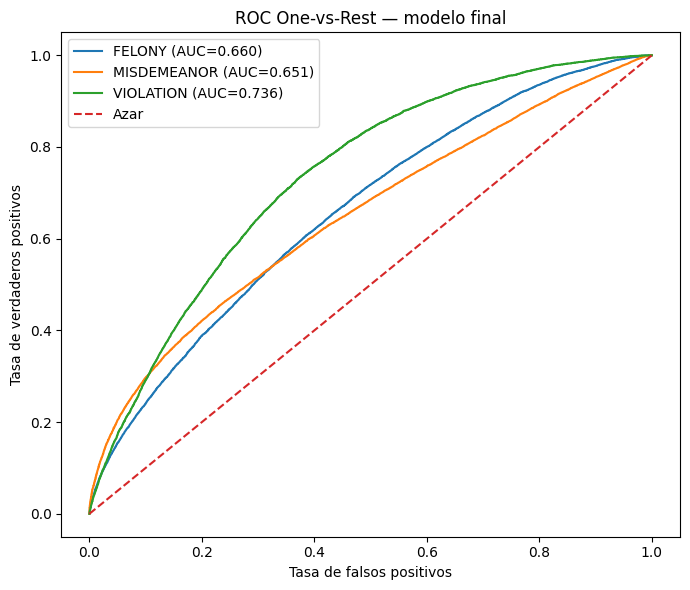

,AUC_OvR
VIOLATION,0.7360
FELONY,0.6600
MISDEMEANOR,0.6506


In [41]:
# ============================================================
# ROC-AUC MULTICLASE ONE-VS-REST
# ============================================================

# Solo se ejecuta cuando el modelo final expone predict_proba.

if proba_final is not None:

    clases_modelo = list(modelo_final.classes_)

    # Binarización One-vs-Rest del target.
    y_bin = label_binarize(
        y_test,
        classes=clases_modelo,
    )

    plt.figure(figsize=(7, 6))

    aucs_por_clase = {}

    # Curva ROC y AUC independientes para cada categoría.
    for i, clase in enumerate(clases_modelo):
        fpr, tpr, _ = roc_curve(
            y_bin[:, i],
            proba_final[:, i],
        )

        auc_clase = roc_auc_score(
            y_bin[:, i],
            proba_final[:, i],
        )

        aucs_por_clase[clase] = auc_clase

        plt.plot(
            fpr,
            tpr,
            label=f"{clase} (AUC={auc_clase:.3f})",
        )

    # Diagonal de referencia correspondiente al azar.
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Azar",
    )

    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("ROC One-vs-Rest — modelo final")
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(
        pd.Series(
            aucs_por_clase,
            name="AUC_OvR",
        )
        .sort_values(ascending=False)
        .to_frame()
        .round(4)
    )

else:
    print(
        "El modelo final no entrega predict_proba; "
        "se omite ROC probabilística."
    )

# 23. Incertidumbre del resultado: bootstrap del F1 macro

Una métrica puntual no tiene incertidumbre cero. Remuestreamos test con reemplazo 1000 veces y calculamos un intervalo empírico del 95% para F1 macro.

In [42]:
# ============================================================
# INTERVALO DE CONFIANZA BOOTSTRAP DEL F1 MACRO
# Versión optimizada
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)

# ------------------------------------------------------------
# Matriz de confusión observada
# ------------------------------------------------------------

cm_boot = confusion_matrix(
    y_test,
    pred_final,
    labels=CLASES,
)

n_test = cm_boot.sum()
n_clases = len(CLASES)

# Probabilidad empírica de cada combinación:
# clase real × clase predicha
prob_celdas = (
    cm_boot.ravel()
    / n_test
)


# ------------------------------------------------------------
# Bootstrap multinomial
# ------------------------------------------------------------

n_bootstrap = 1000

# Cada fila representa una nueva muestra bootstrap
# de la matriz de confusión completa.
muestras = rng.multinomial(
    n=n_test,
    pvals=prob_celdas,
    size=n_bootstrap,
)

muestras = muestras.reshape(
    n_bootstrap,
    n_clases,
    n_clases,
)


# ------------------------------------------------------------
# TP, FP y FN para cada clase
# ------------------------------------------------------------

tp = np.diagonal(
    muestras,
    axis1=1,
    axis2=2,
)

fp = (
    muestras.sum(axis=1)
    - tp
)

fn = (
    muestras.sum(axis=2)
    - tp
)


# ------------------------------------------------------------
# F1 por clase
# ------------------------------------------------------------

denominador = (
    2 * tp
    + fp
    + fn
)

f1_clases_boot = np.divide(
    2 * tp,
    denominador,
    out=np.zeros_like(
        tp,
        dtype=float,
    ),
    where=denominador != 0,
)

# F1 macro de cada remuestreo
f1_boot = (
    f1_clases_boot.mean(axis=1)
)


# ------------------------------------------------------------
# Intervalo de confianza
# ------------------------------------------------------------

ic_inf, ic_sup = np.percentile(
    f1_boot,
    [2.5, 97.5],
)

f1_test = f1_score(
    y_test,
    pred_final,
    average="macro",
    zero_division=0,
)


# ------------------------------------------------------------
# Resultado
# ------------------------------------------------------------

print(
    f"F1 macro test: "
    f"{f1_test:.4f}"
)

print(
    f"IC bootstrap 95%: "
    f"[{ic_inf:.4f}, {ic_sup:.4f}]"
)

print(
    f"Remuestreos bootstrap: "
    f"{n_bootstrap:,}"
)

F1 macro test: 0.4603
IC bootstrap 95%: [0.4561, 0.4642]
Remuestreos bootstrap: 1,000


# 24. Interpretabilidad: importancia por permutación

Aplicamos `permutation_importance` al `Pipeline` completo utilizando las variables crudas del conjunto de test. De esta manera, la importancia queda expresada en las variables originales y no en las columnas resultantes de la codificación.

Para mantener un costo computacional razonable, el análisis se realiza sobre una muestra reproducible de **3.000 observaciones de test** y con **3 repeticiones por variable**. Este análisis es interpretativo y no interviene en la selección del modelo final.


In [43]:
# ============================================================
# IMPORTANCIA POR PERMUTACIÓN
# ============================================================

from sklearn.inspection import permutation_importance

# Presupuesto acotado para mantener el análisis interpretativo reproducible
# sin encarecer la ejecución completa.
N_PERM = 3_000
N_REPEATS_PERM = 3

n_perm = min(
    N_PERM,
    len(X_test),
)

# Muestra reproducible del conjunto de test.
X_perm = X_test.sample(
    n=n_perm,
    random_state=RANDOM_STATE,
)

y_perm = y_test.loc[
    X_perm.index
]

print("=" * 60)
print("IMPORTANCIA POR PERMUTACIÓN")
print("=" * 60)
print(f"Modelo: {modelo_elegido_nombre}")
print(f"Observaciones utilizadas: {len(X_perm):,}")
print(f"Variables evaluadas: {X_perm.shape[1]}")
print(f"Repeticiones por variable: {N_REPEATS_PERM}")
print()
print("Calculando importancia por permutación...")

# La importancia es la caída de F1 macro al romper la asociación
# entre una variable y el target.
perm = permutation_importance(
    estimator=modelo_final,
    X=X_perm,
    y=y_perm,
    scoring="f1_macro",
    n_repeats=N_REPEATS_PERM,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

# Tabla final ordenada de mayor a menor importancia.
importancia = (
    pd.DataFrame({
        "Variable": X_perm.columns,
        "Importancia_media": perm.importances_mean,
        "Importancia_std": perm.importances_std,
    })
    .sort_values(
        "Importancia_media",
        ascending=False,
    )
    .reset_index(drop=True)
)

print()
print("Importancia por permutación completada.")

display(
    importancia.round(5)
)


IMPORTANCIA POR PERMUTACIÓN
Modelo: Random_Forest_ajustado
Observaciones utilizadas: 3,000
Variables evaluadas: 15
Repeticiones por variable: 3

Calculando importancia por permutación...

Importancia por permutación completada.


,Variable,Importancia_media,Importancia_std
0,PREM_TYP_DESC,0.09533,0.00080
1,LOC_OF_OCCUR_DESC,0.03858,0.00081
2,DEMORA_REPORTE_DIAS,0.01569,0.00259
3,CMPLNT_FR_HOUR,0.01567,0.00339
4,CRM_ATPT_CPTD_CD,0.00753,0.00076
5,LONGITUDE,0.00477,0.00143
6,LATITUDE,0.00300,0.00111
7,CMPLNT_FR_MONTH,0.00265,0.00100
8,STATION_NAME,0.00058,0.00079
9,PARKS_NM,-0.00010,0.00042


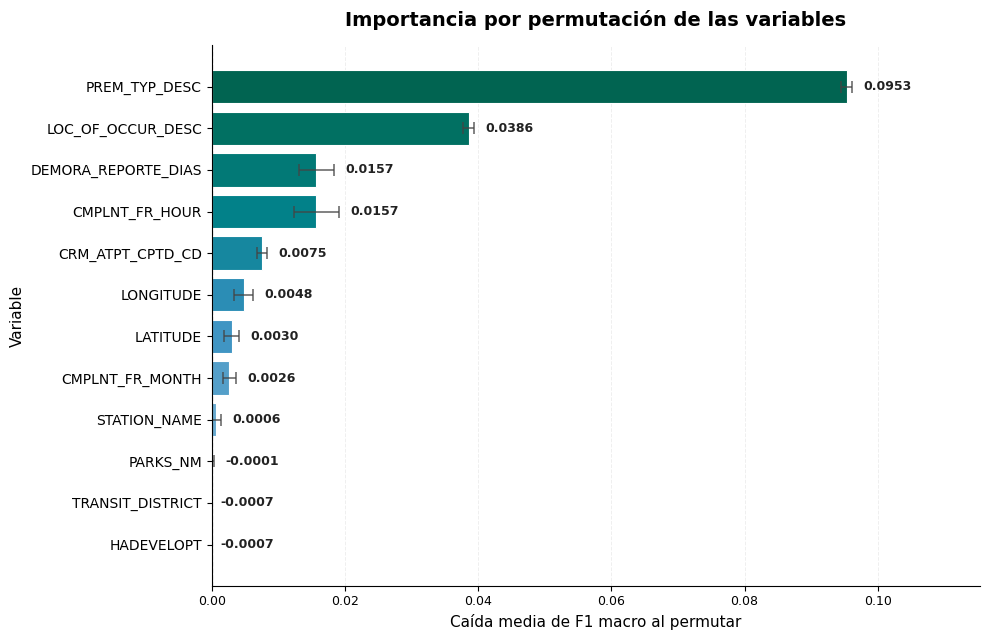

In [44]:
# ============================================================
# VISUALIZACIÓN DE LAS VARIABLES MÁS IMPORTANTES
# ============================================================

# Se seleccionan las 12 variables con mayor importancia media
# y se ordenan de menor a mayor para facilitar la lectura horizontal.

top_imp = (
    importancia
    .head(12)
    .sort_values("Importancia_media")
    .copy()
)


# ------------------------------------------------------------
# Paleta de colores
# ------------------------------------------------------------

# Se utiliza una escala azul-turquesa restringida para evitar
# tonos demasiado claros y mantener buen contraste visual.

colores = plt.cm.PuBuGn(
    np.linspace(
        0.35,
        0.90,
        len(top_imp)
    )
)


# ------------------------------------------------------------
# Construcción del gráfico
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)

barras = ax.barh(
    top_imp["Variable"],
    top_imp["Importancia_media"],
    xerr=top_imp["Importancia_std"],
    color=colores,
    edgecolor="white",
    linewidth=0.8,
    capsize=4,
    error_kw={
        "ecolor": "#444444",
        "elinewidth": 1.1,
        "capthick": 1.1,
        "alpha": 0.85,
    },
)


# ------------------------------------------------------------
# Línea de referencia
# ------------------------------------------------------------

ax.axvline(
    x=0,
    color="#666666",
    linestyle="--",
    linewidth=0.9,
    alpha=0.6,
)


# ------------------------------------------------------------
# Etiquetas de valores
# ------------------------------------------------------------

# Los valores se ubican después del extremo de la barra de error
# para evitar superposiciones.

max_extremo = (
    top_imp["Importancia_media"]
    + top_imp["Importancia_std"]
).max()

desplazamiento = max_extremo * 0.018


for barra, valor, error in zip(
    barras,
    top_imp["Importancia_media"],
    top_imp["Importancia_std"],
):

    posicion_x = (
        valor
        + error
        + desplazamiento
    )

    ax.text(
        posicion_x,
        barra.get_y()
        + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#222222",
        fontweight="bold",
    )


# ------------------------------------------------------------
# Formato de ejes
# ------------------------------------------------------------

ax.set_xlabel(
    "Caída media de F1 macro al permutar",
    fontsize=11,
)

ax.set_ylabel(
    "Variable",
    fontsize=11,
)

ax.set_title(
    "Importancia por permutación de las variables",
    fontsize=14,
    fontweight="bold",
    pad=14,
)


# ------------------------------------------------------------
# Grilla
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.20,
)

ax.set_axisbelow(True)


# ------------------------------------------------------------
# Limpieza visual
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="y",
    labelsize=10,
)

ax.tick_params(
    axis="x",
    labelsize=9,
)


# ------------------------------------------------------------
# Límites del eje X
# ------------------------------------------------------------

# Se reserva espacio suficiente para las barras de error
# y para las etiquetas numéricas.

ax.set_xlim(
    left=0,
    right=max_extremo * 1.20,
)


plt.tight_layout()
plt.show()


# 25. Discriminación no es calibración

La Clase 7 distingue:

- **discriminación:** ordenar correctamente los casos;
- **calibración:** que las probabilidades predichas coincidan con frecuencias observadas.

En este TP usamos probabilidades para ROC-AUC, log-loss y diagnóstico, pero no afirmamos que estén calibradas.

Si el sistema fuera a utilizar probabilidades para decisiones, habría que incorporar un protocolo específico con conjunto de calibración o `CalibratedClassifierCV`, comparar Platt vs. isotónica y reportar Brier score y reliability diagrams.

# 26. Interpretación final con los números reales

Esta sección responde directamente la pregunta de investigación.

La conclusión no se limita a declarar un “ganador”. Integra:

- F1 macro;
- accuracy;
- balanced accuracy;
- AUC;
- comparación contra ambos baselines;
- desempeño por clase;
- efecto del tuning;
- importancia de variables;
- costo del balanceo;
- resultado de las hipótesis H1–H3.

El texto se construye con los outputs de esta misma ejecución para evitar conclusiones genéricas o números escritos a mano.

In [45]:
# ============================================================
# 26. CONCLUSIÓN CUANTITATIVA Y RESPUESTA A LA INVESTIGACIÓN
# ============================================================

import numpy as np
from IPython.display import display, Markdown


# ------------------------------------------------------------
# Identificación de las clases con menor desempeño
# ------------------------------------------------------------

peor_clase_f1 = (
    reporte_clases[
        "f1-score"
    ]
    .idxmin()
)

peor_f1 = (
    reporte_clases.loc[
        peor_clase_f1,
        "f1-score",
    ]
)

peor_clase_recall = (
    reporte_clases[
        "recall"
    ]
    .idxmin()
)

peor_recall = (
    reporte_clases.loc[
        peor_clase_recall,
        "recall",
    ]
)

peor_clase_precision = (
    reporte_clases[
        "precision"
    ]
    .idxmin()
)

peor_precision = (
    reporte_clases.loc[
        peor_clase_precision,
        "precision",
    ]
)


# ------------------------------------------------------------
# Error de clasificación más frecuente
# ------------------------------------------------------------

confusion_principal = (
    errores_df.iloc[0]
)


# ------------------------------------------------------------
# Variable con mayor importancia por permutación
# ------------------------------------------------------------

top_variable = (
    importancia.iloc[0]
)


# ------------------------------------------------------------
# Métricas de referencia
# ------------------------------------------------------------

f1_dummy = (
    tabla_test.loc[
        "Baseline_mayoritaria",
        "F1_macro",
    ]
)

f1_contexto = (
    tabla_test.loc[
        "Baseline_premisa",
        "F1_macro",
    ]
)

acc_dummy = (
    tabla_test.loc[
        "Baseline_mayoritaria",
        "Accuracy",
    ]
)

acc_contexto = (
    tabla_test.loc[
        "Baseline_premisa",
        "Accuracy",
    ]
)

acc_modelo = (
    resultado_modelo[
        "Accuracy"
    ]
)


# ------------------------------------------------------------
# Diferencias respecto de los baselines
# ------------------------------------------------------------

delta_f1_dummy = (
    f1_test
    - f1_dummy
)

delta_f1_contexto = (
    f1_test
    - f1_contexto
)

delta_acc_dummy = (
    acc_modelo
    - acc_dummy
)

delta_acc_contexto = (
    acc_modelo
    - acc_contexto
)


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

auc_final = (
    resultado_modelo.get(
        "ROC_AUC_macro_OvR",
        np.nan,
    )
)

# Se genera una representación textual robusta:
# si AUC no pudo calcularse, la conclusión no falla.

auc_texto = (
    f"{auc_final:.4f}"
    if np.isfinite(auc_final)
    else "No disponible"
)


# ------------------------------------------------------------
# Lectura de la señal predictiva
# ------------------------------------------------------------

if np.isfinite(auc_final):

    if auc_final < 0.70:

        lectura_senal = (
            "Existe señal contextual por encima del azar, pero la capacidad "
            "discriminativa global sigue siendo limitada. El contexto aporta "
            "información, aunque está lejos de reconstruir con gran precisión "
            "la categoría legal cuando se eliminan las variables directamente "
            "ligadas al delito."
        )

    elif auc_final < 0.80:

        lectura_senal = (
            "Existe una señal contextual moderada: el modelo discrimina mejor "
            "que el azar, aunque todavía persiste una superposición considerable "
            "entre las tres clases."
        )

    else:

        lectura_senal = (
            "La señal contextual es fuerte según AUC, aunque la interpretación "
            "debe seguir contrastándose con F1 por clase y matriz de confusión."
        )

else:

    lectura_senal = (
        "El modelo final no permitió calcular AUC; la fuerza de la señal se "
        "interpreta mediante F1 macro, balanced accuracy y errores por clase."
    )


# ------------------------------------------------------------
# Trade-off entre accuracy y F1 macro
# ------------------------------------------------------------

if (
    acc_modelo < acc_dummy
    or acc_modelo < acc_contexto
):

    lectura_tradeoff = (
        "El modelo final tiene menor accuracy que al menos uno de los baselines. "
        "Esto no se oculta: la mejora buscada está en F1 macro y balanced accuracy, "
        "es decir, en repartir mejor el desempeño entre clases en lugar de "
        "maximizar los aciertos globales sobre una distribución dominada por "
        "MISDEMEANOR."
    )

else:

    lectura_tradeoff = (
        "El modelo final no presenta en esta ejecución un costo de accuracy frente "
        "a los baselines. De todos modos, F1 macro sigue siendo el criterio "
        "principal porque la pregunta asigna igual importancia conceptual a "
        "las tres categorías de severidad."
    )


# ------------------------------------------------------------
# Evaluación de las hipótesis
# ------------------------------------------------------------

# H1:
# El modelo final debe superar al baseline contextual en F1 macro.

h1_ok = (
    f1_test
    > f1_contexto
)


# H2:
# Se compara el mejor modelo no lineal contra regresión logística
# utilizando exclusivamente validación cruzada.

mejor_no_lineal_cv = (
    ranking_ml
    .drop(
        index="Regresion_logistica",
        errors="ignore",
    )[
        "F1_macro_CV"
    ]
    .max()
)

f1_log_cv = (
    ranking_ml.loc[
        "Regresion_logistica",
        "F1_macro_CV",
    ]
)

h2_ok = (
    mejor_no_lineal_cv
    > f1_log_cv
)


# H3:
# Se considera respaldada si el tuning aporta menos de 0,005
# de F1 macro o si la regla de selección favorece al modelo
# sin ajuste adicional.

h3_ok = (
    abs(mejora_tuning) < 0.005
    or modelo_elegido_nombre
    != nombre_ajustado
)


estado_h1 = (
    "respaldada"
    if h1_ok
    else "no respaldada"
)

estado_h2 = (
    "respaldada"
    if h2_ok
    else "no respaldada"
)

estado_h3 = (
    "respaldada"
    if h3_ok
    else "no respaldada"
)


# ------------------------------------------------------------
# Construcción automática de la conclusión
# ------------------------------------------------------------

texto = f"""
# Conclusión de la investigación

El modelo seleccionado antes de observar el conjunto de test, mediante validación cruzada y la regla de un error estándar, fue {modelo_elegido_nombre}.

## Desempeño final

- **F1 macro:** {f1_test:.4f}
- **IC bootstrap 95% del F1 macro:** [{ic_inf:.4f}, {ic_sup:.4f}]
- **Balanced accuracy:** {resultado_modelo["Balanced_accuracy"]:.4f}
- **Accuracy:** {acc_modelo:.4f}
- **ROC-AUC macro OvR:** {auc_texto}

## Comparación con baselines

- Δ F1 macro vs. clase mayoritaria: **{delta_f1_dummy:+.4f}**
- Δ F1 macro vs. baseline contextual: **{delta_f1_contexto:+.4f}**
- Δ accuracy vs. clase mayoritaria: **{delta_acc_dummy:+.4f}**
- Δ accuracy vs. baseline contextual: **{delta_acc_contexto:+.4f}**

{lectura_tradeoff}

## Respuesta a la pregunta de investigación

{lectura_senal}

La clase con menor F1 fue **{peor_clase_f1}** ({peor_f1:.4f}).

El menor recall correspondió a **{peor_clase_recall}** ({peor_recall:.4f}) y la menor precisión a **{peor_clase_precision}** ({peor_precision:.4f}).

La confusión absoluta más frecuente fue **{confusion_principal["Clase_real"]} → {confusion_principal["Clase_predicha"]}**, con **{int(confusion_principal["Cantidad"])}** casos.

La variable original con mayor importancia por permutación fue **{top_variable["Variable"]}**. `PREM_TYP_DESC` conserva la identidad de sus 20 categorías más frecuentes mediante One-Hot Encoding y agrupa las restantes como `OTRO`.

## Tuning y parsimonia

El tuning modificó el F1 macro de validación cruzada en **{mejora_tuning:+.4f}**. La magnitud de esta diferencia debe interpretarse junto con la variabilidad entre folds y la regla de un error estándar. Una mejora de unas pocas milésimas no se considera, por sí sola, evidencia suficiente para justificar mayor complejidad.

## Hipótesis

- **H1 — señal contextual por encima de los baselines:** {estado_h1}.
- **H2 — ventaja de relaciones no lineales frente al modelo lineal:** {estado_h2}.
- **H3 — mayor complejidad o tuning no garantiza una mejora sustantiva:** {estado_h3}.

El trabajo no busca sostener que el contexto permita predecir la severidad legal con alta precisión. El objetivo es medir cuánta señal predictiva permanece cuando se eliminan las variables que contienen información directamente ligada a la respuesta, y mostrar de forma transparente el costo de optimizar un criterio que otorgue igual importancia a las tres clases.
"""


# ------------------------------------------------------------
# Presentación de la conclusión
# ------------------------------------------------------------

display(
    Markdown(
        texto
    )
)


# Conclusión de la investigación

El modelo seleccionado antes de observar el conjunto de test, mediante validación cruzada y la regla de un error estándar, fue Random_Forest_ajustado.

## Desempeño final

- **F1 macro:** 0.4603
- **IC bootstrap 95% del F1 macro:** [0.4561, 0.4642]
- **Balanced accuracy:** 0.5136
- **Accuracy:** 0.4679
- **ROC-AUC macro OvR:** 0.6822

## Comparación con baselines

- Δ F1 macro vs. clase mayoritaria: **+0.2318**
- Δ F1 macro vs. baseline contextual: **+0.1995**
- Δ accuracy vs. clase mayoritaria: **-0.0536**
- Δ accuracy vs. baseline contextual: **-0.0584**

El modelo final tiene menor accuracy que al menos uno de los baselines. Esto no se oculta: la mejora buscada está en F1 macro y balanced accuracy, es decir, en repartir mejor el desempeño entre clases en lugar de maximizar los aciertos globales sobre una distribución dominada por MISDEMEANOR.

## Respuesta a la pregunta de investigación

Existe señal contextual por encima del azar, pero la capacidad discriminativa global sigue siendo limitada. El contexto aporta información, aunque está lejos de reconstruir con gran precisión la categoría legal cuando se eliminan las variables directamente ligadas al delito.

La clase con menor F1 fue **VIOLATION** (0.4047).

El menor recall correspondió a **MISDEMEANOR** (0.4031) y la menor precisión a **VIOLATION** (0.2910).

La confusión absoluta más frecuente fue **MISDEMEANOR → VIOLATION**, con **9243** casos.

La variable original con mayor importancia por permutación fue **PREM_TYP_DESC**. `PREM_TYP_DESC` conserva la identidad de sus 20 categorías más frecuentes mediante One-Hot Encoding y agrupa las restantes como `OTRO`.

## Tuning y parsimonia

El tuning modificó el F1 macro de validación cruzada en **+0.0022**. La magnitud de esta diferencia debe interpretarse junto con la variabilidad entre folds y la regla de un error estándar. Una mejora de unas pocas milésimas no se considera, por sí sola, evidencia suficiente para justificar mayor complejidad.

## Hipótesis

- **H1 — señal contextual por encima de los baselines:** respaldada.
- **H2 — ventaja de relaciones no lineales frente al modelo lineal:** respaldada.
- **H3 — mayor complejidad o tuning no garantiza una mejora sustantiva:** respaldada.

El trabajo no busca sostener que el contexto permita predecir la severidad legal con alta precisión. El objetivo es medir cuánta señal predictiva permanece cuando se eliminan las variables que contienen información directamente ligada a la respuesta, y mostrar de forma transparente el costo de optimizar un criterio que otorgue igual importancia a las tres clases.


# 27. Reflexión, limitaciones y pasos a seguir

## 27.1 Qué aprendimos metodológicamente

El resultado más importante del TP no es solamente el nombre del algoritmo final.

El proceso mostró que:

1. un problema mal definido puede dar métricas artificialmente altas por leakage;
2. la representación de una variable también es una decisión de modelado: `PREM_TYP_DESC` perdió identidad bajo Frequency Encoding y por eso se corrigió a One-Hot top-20 + `OTRO`;
3. el baseline es indispensable: superar F1 macro no implica necesariamente superar accuracy;
4. accuracy y F1 macro pueden moverse en direcciones opuestas cuando se ponderan clases, y ese trade-off debe reportarse;
5. `class_weight="balanced"` no se justifica por costumbre: se estudia con un experimento controlado;
6. el preprocesamiento también debe respetar la separación de validación y por eso está dentro del Pipeline;
7. una mejora mínima de tuning no justifica complejidad adicional;
8. la regla 1-SE permite formalizar parsimonia;
9. la importancia predictiva no implica causalidad;
10. discriminación y calibración son problemas diferentes;
11. reproducibilidad implica congelar los datos, no solamente fijar `random_state`.

## 27.2 Limitaciones

### El target es un registro legal

`LAW_CAT_CD` es una clasificación registrada en el sistema del NYPD. El modelo aprende asociaciones con ese registro.

### La señal contextual puede ser limitada

Excluir las variables que describen directamente el delito vuelve el problema metodológicamente más válido, pero también reduce deliberadamente la información disponible. Un F1 o AUC modestos no son necesariamente un fallo del experimento: pueden ser la respuesta sustantiva a la pregunta.

### Sesgo histórico

Los registros policiales reflejan procesos de denuncia, registro y actuación institucional.

### No causalidad

Ni el modelo ni permutation importance permiten afirmar que una variable “cause” mayor o menor severidad legal.

### Validación aleatoria

El split estratificado facilita una comparación homogénea, pero no reproduce completamente un escenario temporal de producción.

### Posibles proxies

Aunque se eliminan variables de leakage y atributos demográficos sensibles, pueden persistir proxies indirectos.

### Agrupación de premisas raras

`PREM_TYP_DESC` conserva las 20 categorías más frecuentes y agrupa las restantes como `OTRO`. Esto mejora respecto del Frequency Encoding anterior, pero sigue siendo una decisión de compresión. Un estudio futuro puede evaluar todas las categorías o modelos con soporte categórico nativo.

### Snapshot mutable en la fuente

El recurso *Current YTD* cambia con el tiempo. Por eso la entrega debe conservar `NYPD_Complaint_Data_Current_2026_Q2.csv` o un enlace persistente al archivo exacto.

## 27.3 Próximos pasos

1. **Validación temporal:** entrenar con meses iniciales y evaluar meses posteriores.
2. **Ablation study:** quitar geografía, tiempo o premisa para cuantificar la contribución de cada bloque.
3. **XGBoost:** comparar otra implementación de Boosting del entorno de la materia.
4. **Optuna:** evaluar si una búsqueda más sofisticada justifica su costo.
5. **Categorías nativas:** comparar One-Hot top-N contra soporte categórico nativo en algoritmos compatibles.
6. **Calibración:** Platt / isotónica si el uso futuro dependiera de probabilidades.
7. **Drift:** medir cambios entre trimestres.
8. **Fairness:** evaluar sesgos y desempeño diferencial antes de cualquier aplicación real.
